# Transformers and flow matching from scratch, in JAX

First of all, let's build a transformer from scratch, and teach it to do regression **in context**: every training
example is a *different* function, and the network only sees a handful of noisy points from it. Nothing about
any one function can actually be stored in the weights, but the model has to work it out from its input.

In the second half, we will reuse the same network as the velocity field of a **flow matching** model, and draw from the posterior
of functions that are consistent with the data.

The functions are drawn from a Gaussian process with a random lengthscale, so the best possible answer is known
exactly. It will be given by `gp_posterior`.

In [65]:
# !pip install -q jax jaxlib matplotlib
# !pip install optax

import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
import optax
import time
from functools import partial



print("jax", jax.__version__, "| devices:", jax.devices())

jax 0.11.2 | devices: [CpuDevice(id=0)]


In [66]:
# [Claude-generated] Make the shared helpers in ML_f26/tools/ importable.
# Jupyter runs this notebook with lab2/ as the working directory, and Python only
# searches that directory (plus installed packages) for modules. tools/ lives one
# level up, so `from tools.plotting import ...` fails until its parent is on sys.path.
import sys
from pathlib import Path

repo_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tools" / "plotting.py").exists())
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from tools.plotting import set_style; set_style()

## The data


In [67]:
X_MAX = 2.0
NOISE_STD = 0.05
ELL_MIN, ELL_MAX = 0.2, 1.0


def rbf(x1, x2, ell):
    """x1: (b, n), x2: (b, m), ell: (b,) -> (b, n, m)"""
    return jnp.exp(-0.5 * (x1[:, :, None] - x2[:, None, :]) ** 2 / ell[:, None, None] ** 2)


def sample_tasks(key, batch, n_ctx, n_tgt=32, ell=None, x_tgt=None):
    """Draw `batch` random functions, each observed (with noise) at n_ctx context and n_tgt target points.
    Returns xc, yc: (batch, n_ctx)   xt, yt: (batch, n_tgt)   ell: (batch,)"""
    k_ell, k_xc, k_xt, k_y = jax.random.split(key, 4)
    if ell is None:
        ell = jnp.exp(jax.random.uniform(k_ell, (batch,), minval=np.log(ELL_MIN), maxval=np.log(ELL_MAX)))
    ell = jnp.broadcast_to(jnp.asarray(ell, jnp.float32), (batch,))
    xc = jax.random.uniform(k_xc, (batch, n_ctx), minval=-X_MAX, maxval=X_MAX)
    if x_tgt is None:
        xt = jax.random.uniform(k_xt, (batch, n_tgt), minval=-X_MAX, maxval=X_MAX)
    else:
        xt = jnp.broadcast_to(x_tgt, (batch, x_tgt.shape[-1]))
    x = jnp.concatenate([xc, xt], axis=1)
    K = rbf(x, x, ell) + (NOISE_STD**2 + 1e-5) * jnp.eye(x.shape[1])
    y = jnp.einsum("bij,bj->bi", jnp.linalg.cholesky(K), jax.random.normal(k_y, x.shape))
    return xc, y[:, :n_ctx], xt, y[:, n_ctx:], ell


def gp_posterior(xc, yc, xt, ell):
    """Exact GP prediction at xt given (xc, yc), if you knew the lengthscale.
    Returns mean: (b, n_tgt), cov: (b, n_tgt, n_tgt)"""
    ell = jnp.broadcast_to(jnp.asarray(ell, jnp.float32), (xc.shape[0],))
    Kcc = rbf(xc, xc, ell) + NOISE_STD**2 * jnp.eye(xc.shape[1])
    Ktc = rbf(xt, xc, ell)
    Ktt = rbf(xt, xt, ell) + NOISE_STD**2 * jnp.eye(xt.shape[1])
    A = jnp.linalg.solve(Kcc, jnp.swapaxes(Ktc, 1, 2))
    mean = jnp.einsum("bct,bc->bt", A, yc)
    return mean, Ktt - Ktc @ A


xc, yc, xt, yt, ell = sample_tasks(jax.random.key(0), batch=1000, n_ctx=10)
mean, cov = gp_posterior(xc, yc, xt, ell)

print(f"target variance               : {float(yt.var()):.4f}")   # predict 0 everywhere
print(f"GP error, 10 points, true ell : {float(((mean - yt) ** 2).mean()):.4f}")   # the best you can do

target variance               : 0.9791
GP error, 10 points, true ell : 0.1456


/var/folders/1f/v2ws8crn4c34nx9fvpdjdb2c0000gn/T/ipykernel_20709/616931590.py:12: UserWarning: The figure layout has changed to tight
  axes[0].set_ylabel("y"); plt.tight_layout(); plt.show()


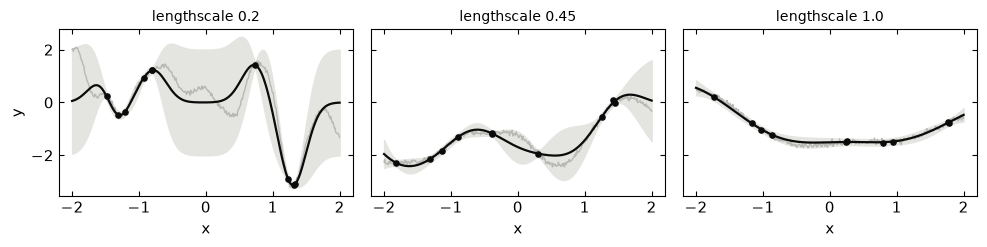

In [68]:
grid = jnp.linspace(-X_MAX, X_MAX, 400)
fig, axes = plt.subplots(1, 3, figsize=(10, 2.6), sharey=True)
for ax, ell_, key in zip(axes, [0.2, 0.45, 1.0], jax.random.split(jax.random.key(1), 3)):
    xc, yc, xt, yt, _ = sample_tasks(key, 1, n_ctx=10, ell=ell_, x_tgt=grid)
    mean, cov = gp_posterior(xc, yc, grid[None], ell_)
    std = jnp.sqrt(jnp.diagonal(cov[0]))
    ax.fill_between(np.array(grid), np.array(mean[0] - 2 * std), np.array(mean[0] + 2 * std), color="#e4e4e0")
    ax.plot(np.array(grid), np.array(yt[0]), color="#b8b8b4", lw=1)
    ax.plot(np.array(grid), np.array(mean[0]), color="#0b0b0b", lw=1.6)
    ax.scatter(np.array(xc[0]), np.array(yc[0]), s=14, color="#0b0b0b", zorder=3)
    ax.set_title(f"lengthscale {ell_}", fontsize=10); ax.set_xlabel("x")
axes[0].set_ylabel("y"); plt.tight_layout(); plt.show()

---
## 1. Attention

Every observed point becomes a token `(x, y, 1)`; every point where you want a prediction is also  a token
`(x, 0, 0)`.

Write multi-head self-attention, `attention(params, h, mask)`, where `mask[i, j]` says whether token `i` may look
at token `j`. Then a transformer block: layer norm, attention, residual, MLP, residual.

Choose the mask.  What are targets allowed to look at? should they receive information from other targets?

In [69]:
def init_attention(key, width,n_heads):
    """Initiates the weights for the attention network.
    params: 
    Key: int, jax  key for randomization
    width: int, embedding dimension
    n_heads: int, number of attention heads
    returns: four matrices to be learned"""

    k1, k2, k3, k4 = jax.random.split(key,4)
    queries = jax.random.normal(k1,shape=(width,width)) / jnp.sqrt(width)
    keys    = jax.random.normal(k2,shape=(width,width)) / jnp.sqrt(width)
    values  = jax.random.normal(k3,shape=(width,width)) / jnp.sqrt(width)
    # output projection mixes info from across heads
    output_projection = jax.random.normal(k4,shape=(width,width)) / jnp.sqrt(width)
    return (queries, keys, values, output_projection)
    

def attention(params, tokens, mask, n_heads):
    """Runs the attention mechanism forward"""
    n_tokens = len(tokens[:,0])
    width = len(tokens[0,:])
    d_k = width // n_heads # length of each head
    
    # pass the learned weights as parameters
    query_matrix, key_matrix, value_matrix, output_projection = params

    # query vector for each token is the token's embedding times the query weight matrix
    Q = jnp.matmul(tokens,query_matrix) # has shape (n_tokens, width)
    K = jnp.matmul(tokens,key_matrix) # has shape (n_tokens, width)
    V = jnp.matmul(tokens,value_matrix) # shape (n_tokens, width)

    # split into multiple heads
    outputs = []
    for h in range(n_heads):
        i_start = h*d_k
        i_stop = i_start + d_k
        # split matrices into block for just this head
        Q_h = Q[:,i_start:i_stop]
        K_h = K[:,i_start:i_stop]
        V_h = V[:,i_start:i_stop]
        scores_h = Q_h @ K_h.T / jnp.sqrt(d_k)
        # apply mask so tokens only read context points, not target points
        # jnp.where replaces all instances of False in mask with -inf
        scores_h = jnp.where(mask,scores_h,-jnp.inf)
        output_h = jax.nn.softmax(scores_h, axis=-1) @ V_h
        outputs.append(output_h)
    output = jnp.concatenate(outputs,axis=-1)
    output_mixedheads = output @ output_projection

    return output_mixedheads

def layernorm(tokens,gamma,beta,eps = 1e-5):
    """ compute layer norm on each token's embedding vector
    input: tokens: list of embedded tokens
    eps: used to avoid dividing by 0
    gamma, beta are learned params, need to be trained"""
    mean = jnp.mean(tokens,axis=-1,keepdims=True)
    var = jnp.var(tokens,axis=-1,keepdims=True)
    tokens = (tokens-mean)/jnp.sqrt(var+eps) # should subtract mean from each token's vector
    tokens = gamma*tokens + beta
    return tokens

Check this by running n_heads = 1 and compare to full attention with no splitting

---
## 2. The transformer

Embed the tokens (a small MLP is fine), stack transformer blocks, and read out a mean and a log-variance at each target.
We will assume a Gaussian negative log-likelihood during training. Some reasonable numbers are width 64, 4 heads, 4 layers.

Each step: get a batch of functions, with a random number of context points between 3 and 30, and 30'ish targets as well. 
Feel free to use jax libraries for the optimiser and weight updates (no need to use your solution from the previous tutorial!). 
The number of context points changes the shapes, so `jax.jit` recompiles once per value. That's fine, otherwise you'd need to add some padding

Build the embedding MLP: this model should take the 3 input values for each token (x,y, isContext) (isContext = 1 if context point and = 0 if target point)
and return a vector len 64.

In [70]:
# Build the embedding MLP
# This model should take the 3 values of tokens (x)
def init_mlp(key,layer_sizes):
    n_layers = len(layer_sizes)
    keys = jax.random.split(key,2*(n_layers - 1)) # only need weights and biases for hidden and final layer
    biases = []
    weights = []
    for i, size in enumerate(layer_sizes[1:]): # don't need weights + biases for input layer
        std = jnp.sqrt(2 / layer_sizes[i])
        bias = jax.random.normal(keys[2*i],size) / 10 # try initialize with non-zero biases
        weight = jax.random.normal(keys[2*i+1],(layer_sizes[i],size)) * std
        biases.append(bias)
        weights.append(weight)
    return (weights, biases)

def mlp(params,tokens):
    """Embeds the list of tokens (x,y,isContext) into 64 dim vectors
    inputs:
    params: tuple (weights, biases) with size (n_layers, n_layers)
    tokens: list of tuples for each context+target token

    returns: list of embedding vectors for each token"""
    n_layers = len(params[0]) # length of weights list
    a = tokens
    for i in range(n_layers):
        W = params[0][i]
        b = params[1][i]
        if i < n_layers-1: a = jax.nn.gelu(a @ W + b)
        else: a = a @ W + b

    return a

Create the transformer block: layer norm, attention, residual, MLP, residual

def transformer(n_blocks):

In [ ]:
def init_params(key,embedding_dim=64,
                n_heads=4,embedding_size=(3,64,64),umembedding_size=(64,64,2),
                forward_mlp_size=(64,64*4,64),n_blocks=4):
    k_embed, k_unemb,k_f,k_atts = jax.random.split(key,4)
    k_forward = jax.random.split(k_f,n_blocks)
    k_atts = jax.random.split(k_atts,n_blocks)
    
    embedding_params = init_mlp(k_embed,embedding_size)
    unembedding_params = init_mlp(k_unemb,umembedding_size)
    

    # store one copy of MLP params for each block using dict
    # and one copy of attention params for each block
    attention_params = {}
    forward_mlp_params = {}
    layernorm1_params = {}
    layernorm2_params = {}

    gamma_i = jnp.ones(embedding_dim)
    beta_i = jnp.zeros(embedding_dim)
    layernormfinal_params = (gamma_i, beta_i)
    
    for i in range(n_blocks):
        # keys
        k_thisforward = k_forward[i]
        k_att = k_atts[i]

        forward_mlp_params[f"block_{i}"] = init_mlp(k_thisforward,forward_mlp_size)
        attention_params[f"block_{i}"] = init_attention(k_att,embedding_dim,n_heads)
        layernorm1_params[f"block_{i}"] = (gamma_i, beta_i)
        layernorm2_params[f"block_{i}"] = (gamma_i, beta_i)
        #blocks.append({"ln1:": (gamma_i,beta_i), "ln2": (gamma_i,beta_i)
                       #"attention:": (att_params_i), "mlp"})


    return (embedding_params, attention_params,layernorm1_params,
            forward_mlp_params,layernorm2_params,
            layernormfinal_params,unembedding_params)

def transformer(params,tokens_raw,mask,n_heads,n_blocks=4):
    """Runs transformer forward to combine embedding,layernorm,attention,
    layernorm,MLP,unembedding.
    Output: (predicted y, log of pred var): shape (n_tokens,2)"""
    # call params
    embedding_params, attention_params,layernorm1_params,forward_mlp_params,layernorm2_params,layernormfinal_params,unembedding_params = params
    # embed tokens
    tokens = mlp(embedding_params,tokens_raw) # embedded tokens

    # do layer norm->attention->residual->MLP->residual for each block
    for i in range(n_blocks):
        att_params_i = attention_params[f"block_{i}"]
        forward_params_i = forward_mlp_params[f"block_{i}"]
        gamma1, beta1 = layernorm1_params[f"block_{i}"]
        gamma2, beta2 = layernorm2_params[f"block_{i}"]

        # apply attention and add to residual
        # apply layer norm to tokens before passing to attention
        tokens += attention(att_params_i,layernorm(tokens,gamma1,beta1),mask,n_heads)
        # apply forward pass MLP and add to residual
        tokens += mlp(forward_params_i,layernorm(tokens,gamma2,beta2))

    #apply final layer norm after last block
    gamma_f, beta_f = layernormfinal_params
    tokens = layernorm(tokens,gamma_f,beta_f)

    # use MLP to unembed: send token vectors -> (x,y)
    # shape (n_tokens,2), each output [predicted y, log of pred var)
    output_unembedded = mlp(unembedding_params,tokens) 
    return output_unembedded

def run_transformer(params,xc,yc,xt,yt):
    """Running the transformer forward
    Inputs params (learned and updated)
    xc shape (n_batches,n_ctx), etc.
    Outputs y_pred,log_var"""

    n_ctx, n_tgt = xc.shape[1], xt.shape[1]
    tokens = make_tokens(xc,yc,xt)
    mask = make_mask(n_ctx,n_tgt)
    # for a single fxn's token, run transofmrer with shared params and mask
    # vmap applies to every row of the batch axis
    out = jax.vmap(lambda token: transformer(params,token,mask,N_HEADS))(tokens)
    y_pred, log_var = out[:, n_ctx:, 0], out[:, n_ctx:, 1]
    return y_pred,log_var

def loss_fn(params,xc,yc,xt,yt):
    """Calculates loss by running the transformer forward
    Inputs params (learned and updated)
    xc shape (n_batches,n_ctx), etc.
    Outputs ave NLL over all batches"""
    
    y_pred, log_var = run_transformer(params,xc,yc,xt,yt)
    neg_log_likelihood = 0.5 * (log_var + (y_pred - yt)**2 * jnp.exp(-log_var)) # array of len n target pts
    return jnp.mean(neg_log_likelihood)

In [72]:
def make_tokens(xc, yc, xt):
    """Makes the tokens for the transformer.
    Inputs a set of context points (xc,yc) and a set of target points xt
    Each tokens has structure (x,y,flag), where flag=1 is context,flag=0 cxt
    The total token output is:
    [[xc1,xc2,...xt1,xt2,...],[yc1,yc2,..0,0,..],[1,1,...,0,0...]]"""
    x_all = jnp.concatenate([xc,xt],axis=1)
    y_all = jnp.concatenate([yc,jnp.zeros_like(xt)],axis=1)
    flags = jnp.concatenate([jnp.ones_like(xc),jnp.zeros_like(xt)],axis=1)
    tokens = jnp.stack([x_all,y_all,flags],axis=-1)
    return tokens

def make_mask(n_ctx,n_tgt):
    n = n_ctx + n_tgt
    mask = jnp.zeros((n,n),dtype=bool)
    # boolean matrix with blocks ((1,0),(1,0))
    # all context sees context, tgt sees context should be True
    mask = mask.at[:n_ctx,:n_ctx].set(True)
    mask = mask.at[n_ctx:,:n_ctx].set(True)
    return mask

In [73]:
@partial(jax.jit, static_argnames="loss_fn")
def train_step(params,loss_fn,opt_state,xc,yc,xt,yt):
    """Apply one step of training.
    Input params (current state of all transformer parameters),
    opt_state (current set of parameters for optimizer, eg Adam's beta),
    xc,yc,xt,yt to be pulled from sample.
    Output: updated params, opt_state, loss (calculated with jax gradients)"""
    loss, grads = jax.value_and_grad(loss_fn)(params,xc,yc,xt,yt)
    updates, opt_state = opt.update(grads,opt_state,params)
    params = optax.apply_updates(params,updates)
    return params, opt_state, loss

In [74]:
# training
opt = optax.adam(1e-3) #pick adam as optimizer, learning rate from previous lab
key = jax.random.key(19)
key, k_init = jax.random.split(key,2)

params = init_params(k_init)
opt_state = opt.init(params)

N_BATCH = 64
N_TGT = 32
N_HEADS = 4

start = time.time()

losses = []
times = []
n_trainsteps = 10000
trainsteps = np.arange(n_trainsteps)
for step in trainsteps:
    # split key so sample tasks have different random seed than transformer
    key, key_data = jax.random.split(key,2)
    # draw random # context points
    n_ctx = np.random.randint(3,31)
    # create the tasks
    xc, yc, xt, yt, ell = sample_tasks(key_data,batch=N_BATCH,n_ctx=n_ctx,n_tgt=N_TGT)
    # run training forward, runs whole transformer and NLL loss calc and gradients
    params, opt_state, loss = train_step(params,loss_fn,opt_state,xc,yc,xt,yt)
    losses.append(float(loss))
    times.append(time.time()-start)
    if step % 1000 == 0: print(f"Step: {step}, loss: {loss:.2f}, time: {(time.time()-start):.1f}s")


Step: 0, loss: 1.49, time: 1.1s
Step: 1000, loss: -0.74, time: 66.7s
Step: 2000, loss: -1.17, time: 102.8s
Step: 3000, loss: -1.61, time: 139.7s
Step: 4000, loss: -0.15, time: 176.1s
Step: 5000, loss: -1.67, time: 212.0s
Step: 6000, loss: -1.75, time: 248.5s
Step: 7000, loss: -0.94, time: 284.5s
Step: 8000, loss: -1.43, time: 321.0s
Step: 9000, loss: -1.78, time: 357.2s


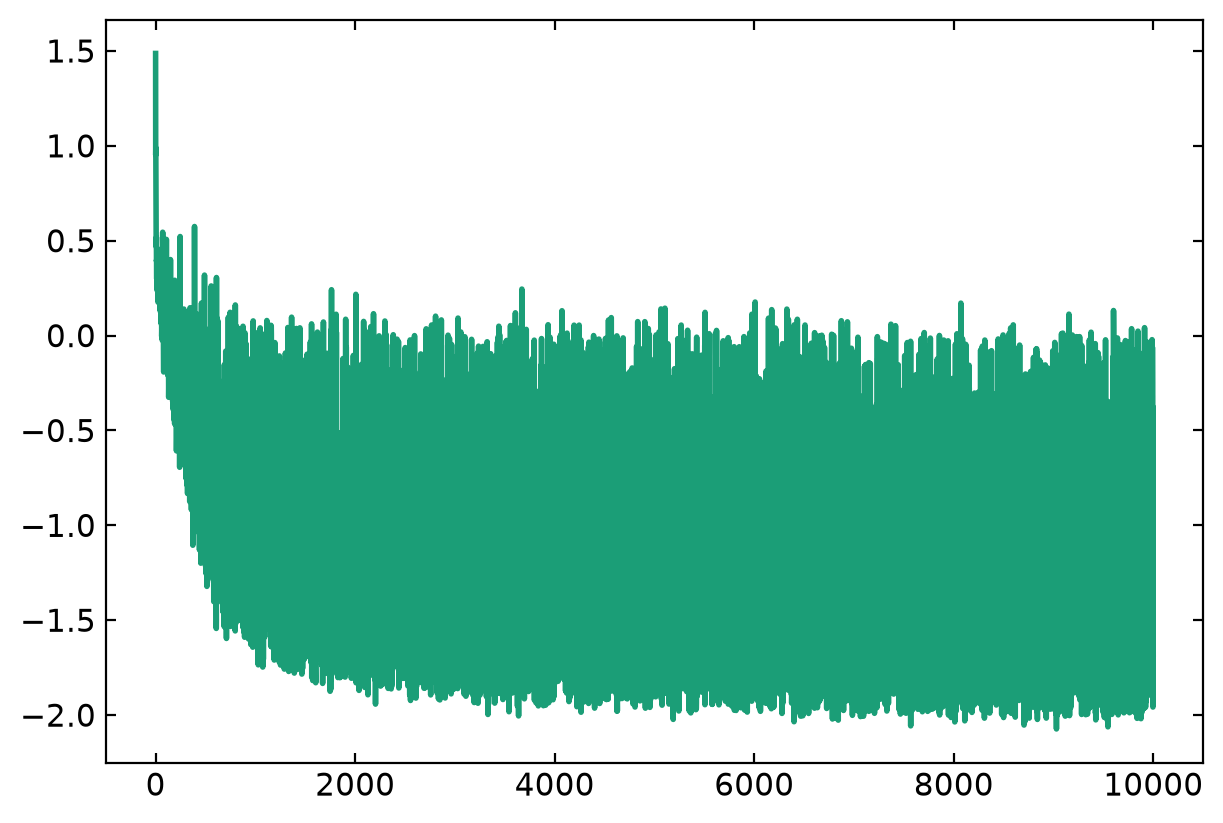

In [75]:
# plot loss
plt.figure(figsize=(6,4),dpi=200)
plt.plot(trainsteps,losses)

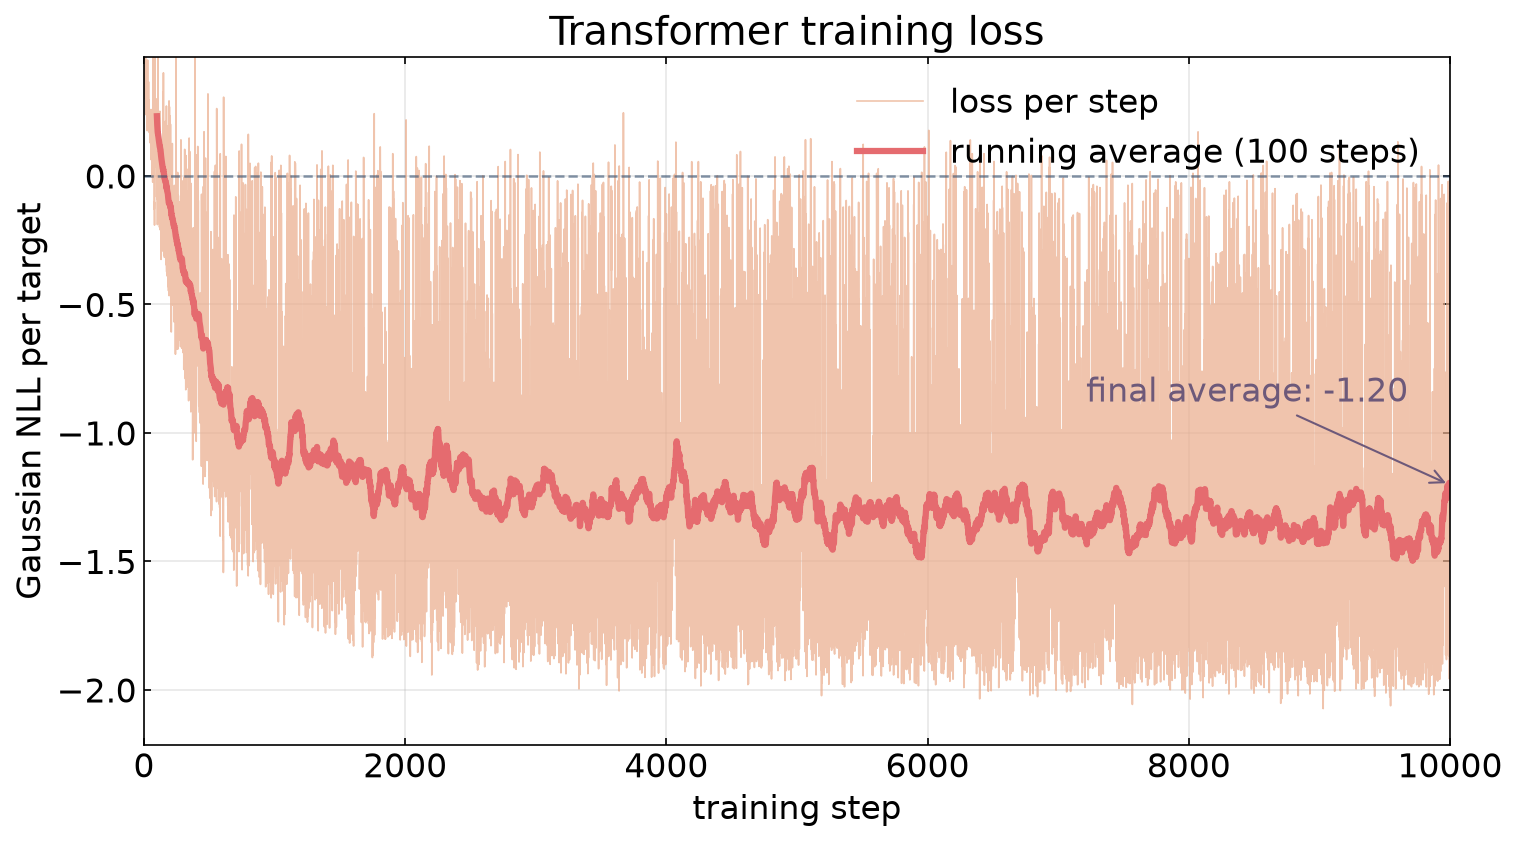

In [76]:
# [Claude-generated] Training loss with a running average.
# The raw loss jumps around because every step draws a new n_ctx (3-30) and new
# functions, so a moving average is plotted on top to show the trend underneath.
SUNSET = {"dusk": "#355070", "plum": "#6d597a", "rose": "#b56576",
          "coral": "#e56b6f", "peach": "#eaac8b", "gold": "#f6bd60"}

window = 100
loss_arr = np.asarray(losses)
running_avg = np.convolve(loss_arr, np.ones(window) / window, mode="valid")
avg_steps = np.asarray(trainsteps)[window - 1:]   # each average covers the `window` steps ending here

with plt.rc_context({"font.size": 16}):
    fig, ax = plt.subplots(figsize=(10, 5.5), dpi=150, layout="constrained")
    ax.plot(trainsteps, loss_arr, color=SUNSET["peach"], lw=0.8, alpha=0.7, label="loss per step")
    ax.plot(avg_steps, running_avg, color=SUNSET["coral"], lw=3, label=f"running average ({window} steps)")
    ax.axhline(0, color=SUNSET["dusk"], lw=1.2, ls="--", alpha=0.6)

    # clip the y-range to the bulk of the raw losses so rare spikes don't squash the curve
    lo, hi = np.percentile(loss_arr, [0.5, 99.5])
    ax.set_ylim(lo - 0.1 * (hi - lo), hi + 0.1 * (hi - lo))
    ax.set_xlim(0, len(loss_arr))

    ax.annotate(f"final average: {running_avg[-1]:.2f}", xy=(avg_steps[-1], running_avg[-1]),
                xytext=(-20, 40), textcoords="offset points", ha="right", color=SUNSET["plum"],
                arrowprops=dict(arrowstyle="->", color=SUNSET["plum"]))
    ax.set_xlabel("training step")
    ax.set_ylabel("Gaussian NLL per target")
    ax.set_title("Transformer training loss")
    ax.grid(alpha=0.3)
    ax.legend(frameon=False)
    plt.show()

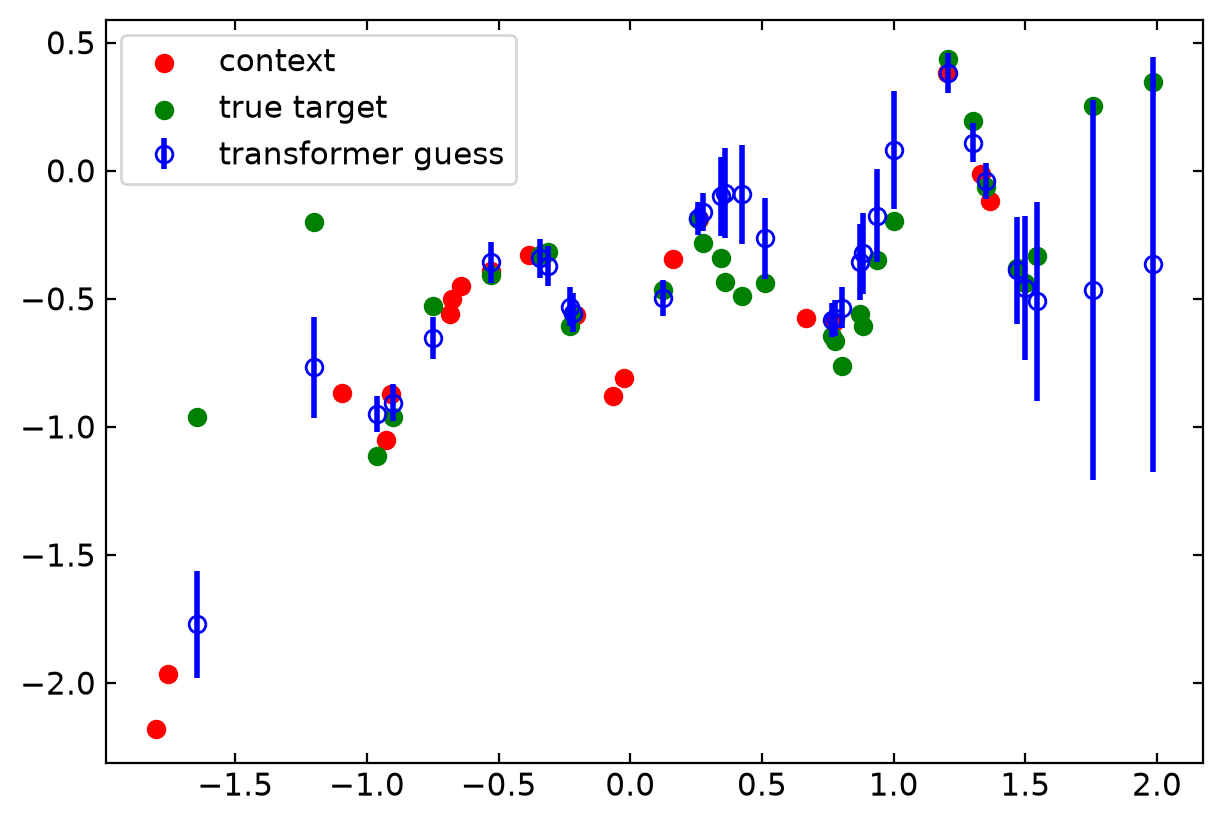

In [82]:
# make a plot of what the output actually was for one batch
thisxc = xc[0]
thisyc = yc[0]
thisxt = xt[0]
thisyt = yt[0]
plt.figure(figsize=(6,4),dpi=200)
plt.scatter(thisxc,thisyc,color='red',label='context')
plt.scatter(thisxt,thisyt,color="green",label='true target')

y_pred, log_var = run_transformer(params,xc,yc,xt,yt)
thisypred = y_pred[0]
thisvar = np.exp(log_var[0])
plt.errorbar(thisxt,thisypred,yerr=np.sqrt(thisvar),linestyle='',
             fmt='bo', markerfacecolor='none', markeredgecolor='blue',
             label='transformer guess')
plt.legend()

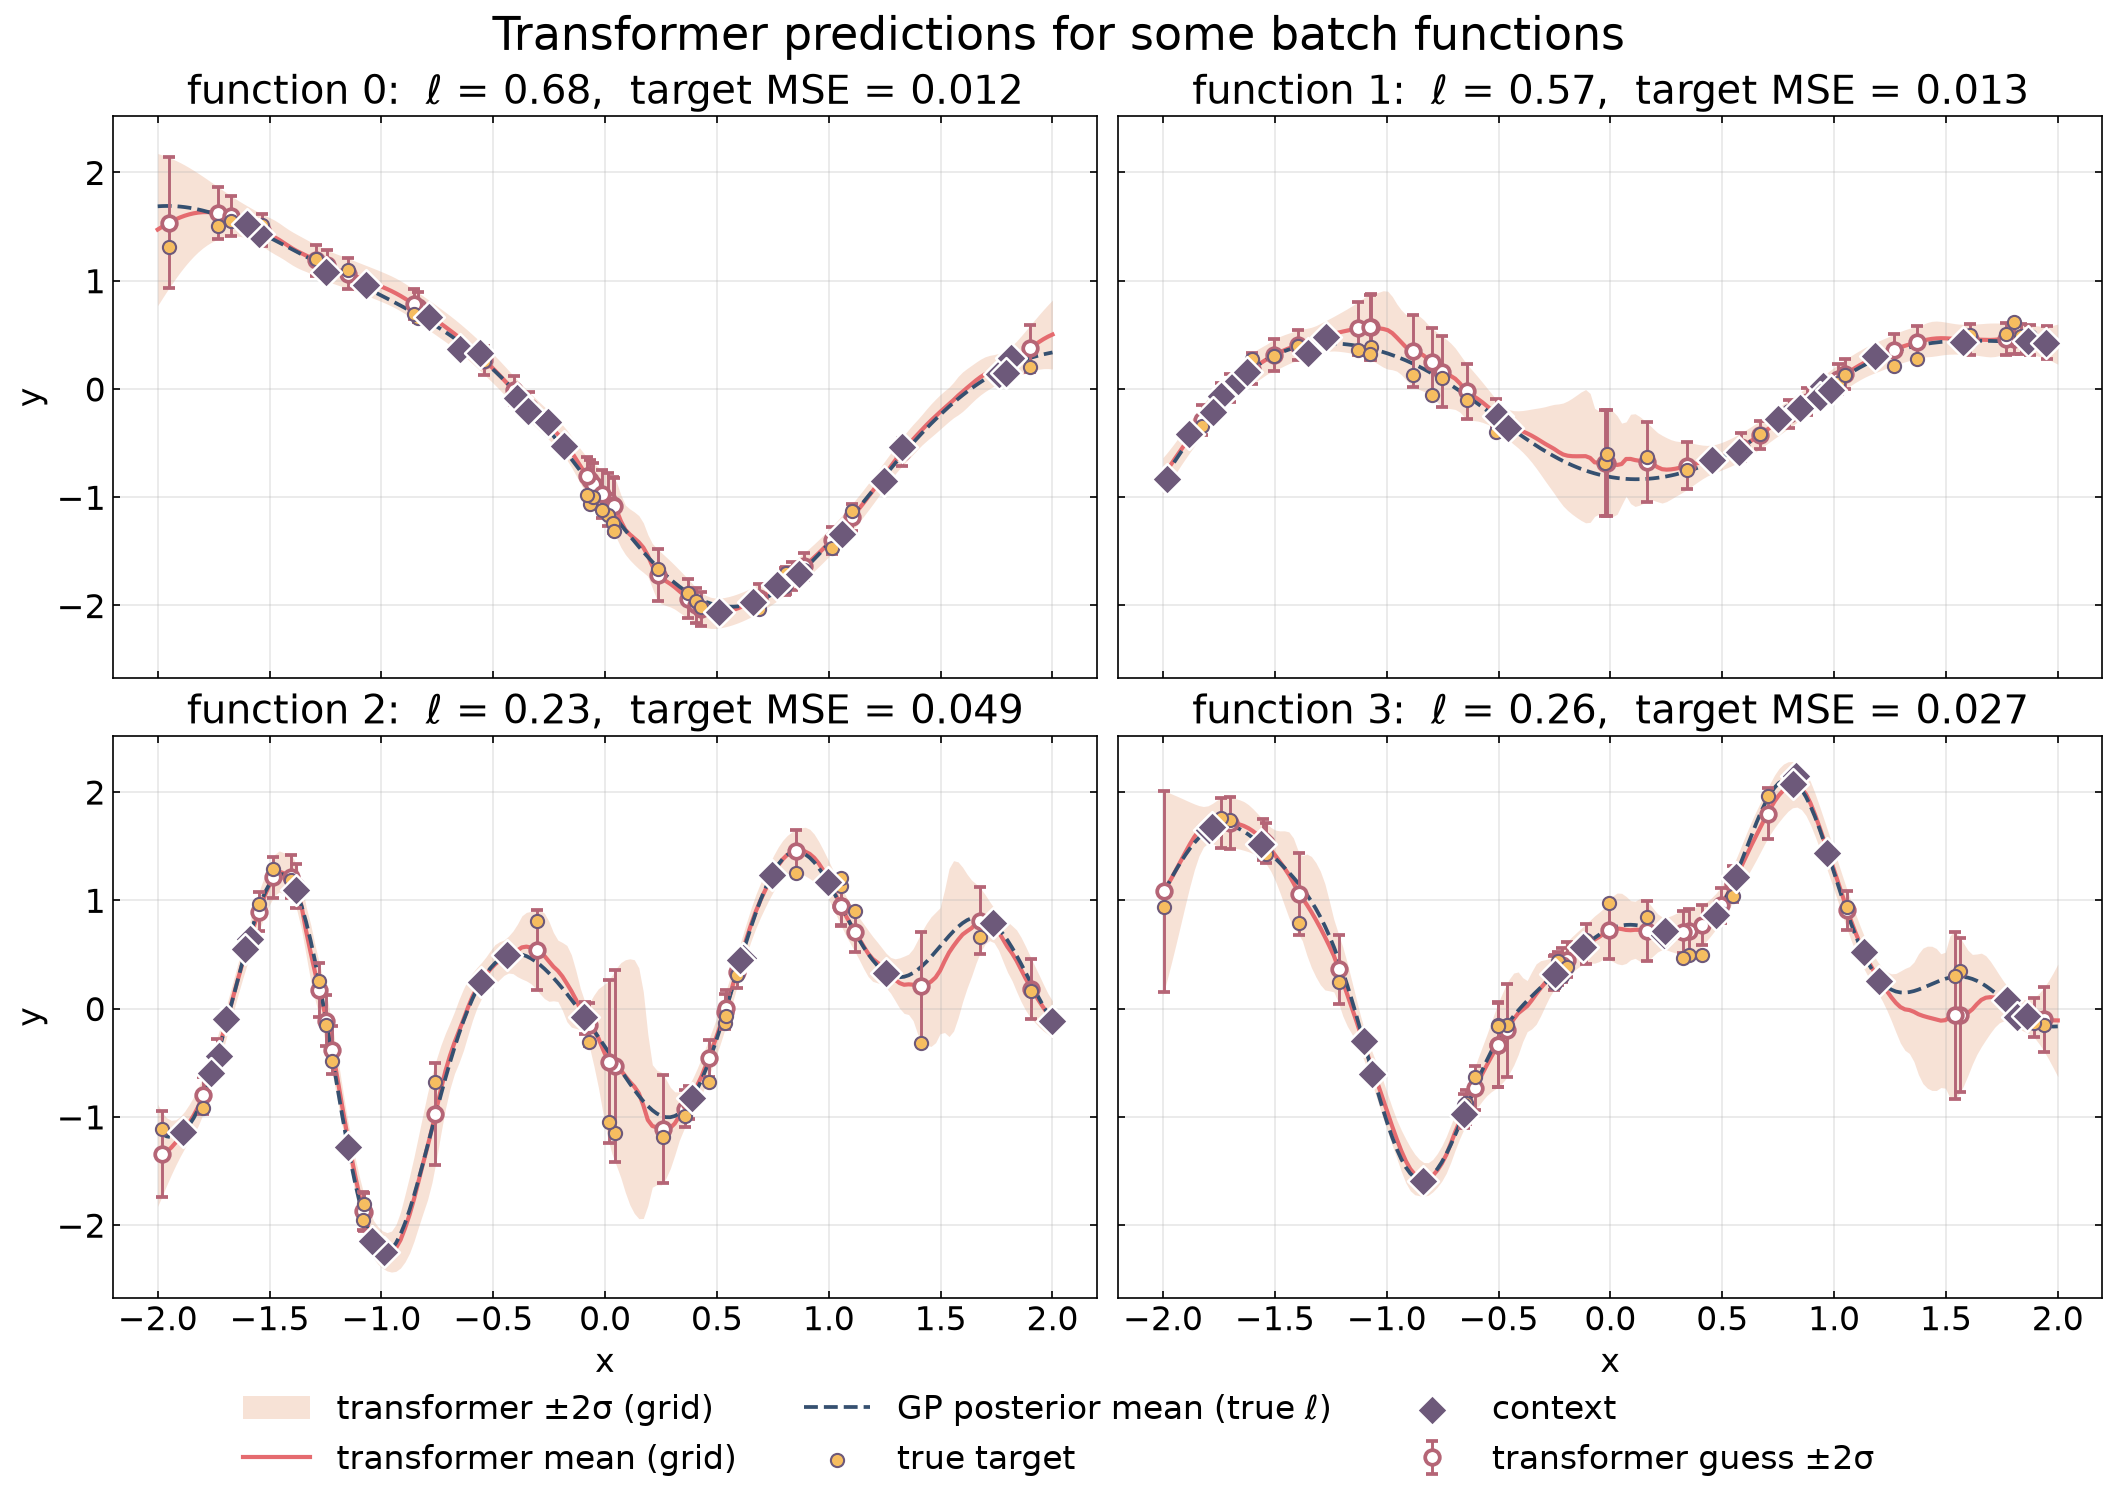

In [78]:
# [Claude-generated] Transformer predictions vs. the truth for four functions from the batch.
# Points: true (noisy) target values, and the transformer's guess at each target x with
# ±2σ error bars (σ = exp(log_var / 2)). Line + band: the transformer evaluated on a dense
# x-grid, which is valid because targets can't see each other (see make_mask), so each grid
# point is predicted from the context alone, exactly like a real target. Dashed line: the
# exact GP posterior mean with the true lengthscale, i.e. the best possible prediction.
SUNSET = {"dusk": "#355070", "plum": "#6d597a", "rose": "#b56576",
          "coral": "#e56b6f", "peach": "#eaac8b", "gold": "#f6bd60"}

n_show = 4
grid_x = jnp.linspace(-X_MAX, X_MAX, 200)
grid_b = jnp.broadcast_to(grid_x, (n_show, grid_x.size))

pred_t, logvar_t = run_transformer(params, xc[:n_show], yc[:n_show], xt[:n_show], yt[:n_show])
pred_g, logvar_g = run_transformer(params, xc[:n_show], yc[:n_show], grid_b, grid_b)  # yt arg is unused
gp_mean_g, _ = gp_posterior(xc[:n_show], yc[:n_show], grid_b, ell[:n_show])
std_t = np.exp(0.5 * np.asarray(logvar_t))
std_g = np.exp(0.5 * np.asarray(logvar_g))

with plt.rc_context({"font.size": 16}):
    fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=150, sharex=True, sharey=True, layout="constrained")
    for b, ax in enumerate(axes.flat):
        ax.fill_between(grid_x, pred_g[b] - 2 * std_g[b], pred_g[b] + 2 * std_g[b],
                        color=SUNSET["peach"], alpha=0.35, lw=0, label="transformer ±2σ (grid)")
        ax.plot(grid_x, pred_g[b], color=SUNSET["coral"], lw=2, label="transformer mean (grid)")
        ax.plot(grid_x, gp_mean_g[b], color=SUNSET["dusk"], lw=1.8, ls="--", label="GP posterior mean (true ℓ)")
        ax.errorbar(xt[b], pred_t[b], yerr=2 * std_t[b], fmt="o", ms=7, mfc="white", mec=SUNSET["rose"],
                    mew=1.8, ecolor=SUNSET["rose"], elinewidth=1.4, capsize=3, label="transformer guess ±2σ")
        ax.scatter(xt[b], yt[b], s=40, color=SUNSET["gold"], edgecolor=SUNSET["plum"], lw=1, zorder=4,
                   label="true target")
        ax.scatter(xc[b], yc[b], s=110, marker="D", color=SUNSET["plum"], edgecolor="white", lw=1.2,
                   zorder=5, label="context")

        mse = float(jnp.mean((pred_t[b] - yt[b]) ** 2))
        ax.set_title(f"function {b}:  ℓ = {float(ell[b]):.2f},  target MSE = {mse:.3f}")
        ax.grid(alpha=0.3)
    for ax in axes[1]:
        ax.set_xlabel("x")
    for ax in axes[:, 0]:
        ax.set_ylabel("y")

    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside lower center", ncols=3, frameon=False)
    fig.suptitle(f"Transformer predictions for some batch functions", fontsize=22)
    plt.show()

## Making a plot of the model performance vs. lengthscale

Used Claude with this prompt: I want to create a plot that shows the transformer performance as a function of ell, basically how much does the parameter for the gaussian process determine how well the model learns? So I think I need a loss function that doesn't just output the mean of all the losses in the batch, but actually outputs the loss as a list of the losses for each batch function. then i could also extract a list of ell for each batch and plot as a scatter plot, perhaps increasing batch size to 256 or something. If it's as simple as what i'm suggesting, add another cell below the transformer predictions with this plot. 

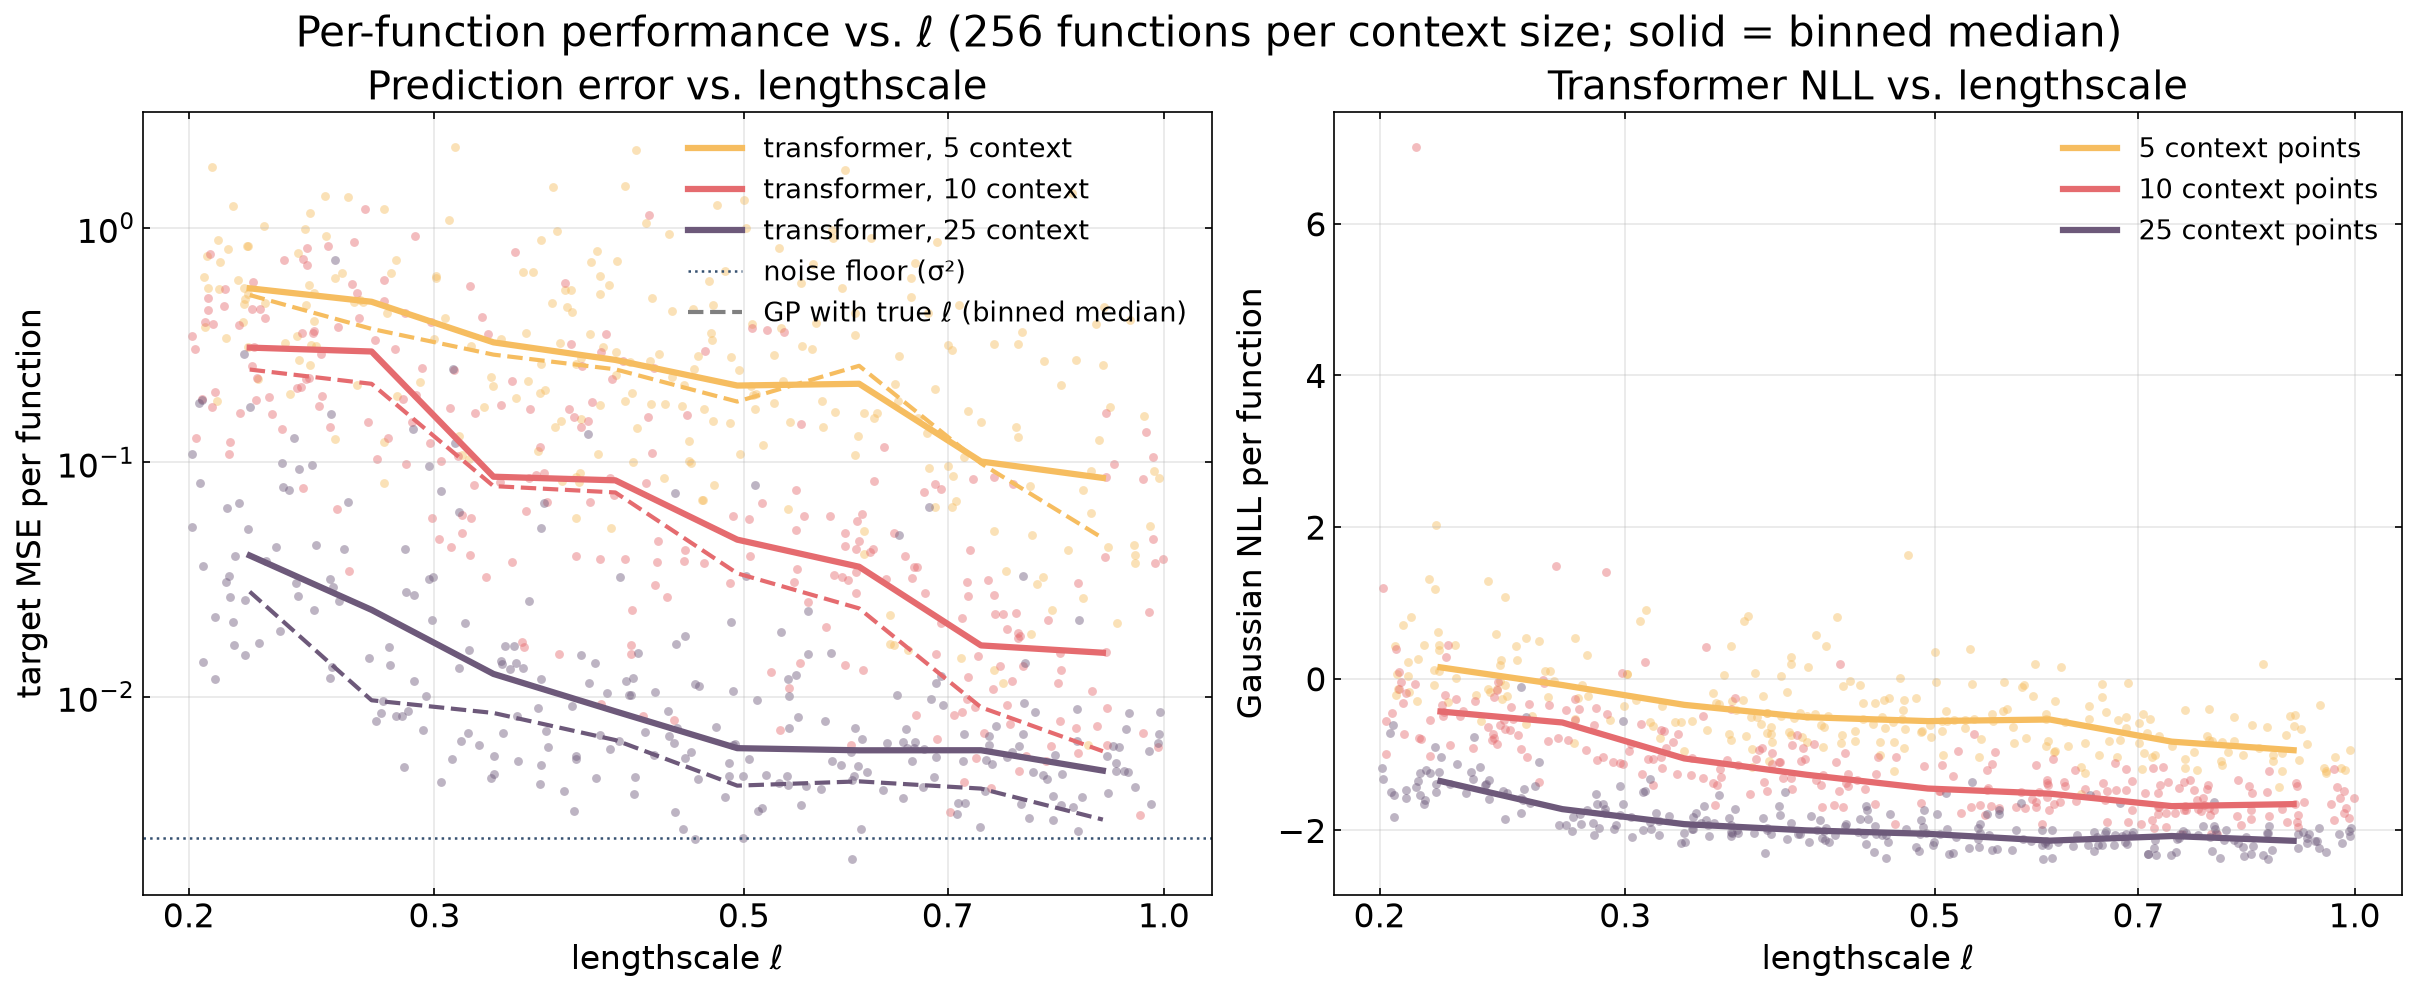

In [79]:
# [Claude-generated] How does the lengthscale ℓ affect transformer performance?
# Draws a fresh batch of 256 functions at a few fixed context sizes and scores every
# function separately: averaging over the targets only (axis=1), not over the batch,
# gives one loss per function to scatter against that function's ℓ. n_ctx is held fixed
# per color because it also strongly affects error, and mixing it in would blur the trend.
# Dashed lines: exact GP with the true ℓ on the same functions, binned. This shows how hard
# each ℓ is for *any* model, so the gap between solid and dashed is the transformer's own shortfall.
SUNSET = {"dusk": "#355070", "plum": "#6d597a", "rose": "#b56576",
          "coral": "#e56b6f", "peach": "#eaac8b", "gold": "#f6bd60"}


def per_function_scores(xc, yc, xt, yt, ell):
    """Returns (transformer MSE, transformer NLL, GP MSE), each of shape (batch,)"""
    y_pred, log_var = run_transformer(params, xc, yc, xt, yt)
    nll = 0.5 * (log_var + (y_pred - yt) ** 2 * jnp.exp(-log_var))
    gp_mean, _ = gp_posterior(xc, yc, xt, ell)
    return (jnp.mean((y_pred - yt) ** 2, axis=1), jnp.mean(nll, axis=1),
            jnp.mean((gp_mean - yt) ** 2, axis=1))


n_eval = 256
ctx_sizes = [5, 10, 25]
ctx_colors = [SUNSET["gold"], SUNSET["coral"], SUNSET["plum"]]
ell_bins = np.geomspace(ELL_MIN, ELL_MAX, 9)
bin_centers = np.sqrt(ell_bins[:-1] * ell_bins[1:])


def binned_median(ell_vals, scores):
    idx = np.digitize(ell_vals, ell_bins) - 1
    return np.array([np.median(scores[idx == i]) for i in range(len(bin_centers))])


with plt.rc_context({"font.size": 16}):
    fig, (ax_mse, ax_nll) = plt.subplots(1, 2, figsize=(16, 6.5), dpi=150, layout="constrained")
    for n_c, color, k in zip(ctx_sizes, ctx_colors, jax.random.split(jax.random.key(123), len(ctx_sizes))):
        xc_e, yc_e, xt_e, yt_e, ell_e = sample_tasks(k, n_eval, n_ctx=n_c, n_tgt=N_TGT)
        mse_t, nll_t, mse_gp = (np.asarray(s) for s in per_function_scores(xc_e, yc_e, xt_e, yt_e, ell_e))
        ell_e = np.asarray(ell_e)

        ax_mse.scatter(ell_e, mse_t, s=18, color=color, alpha=0.45, lw=0)
        ax_mse.plot(bin_centers, binned_median(ell_e, mse_t), color=color, lw=3, label=f"transformer, {n_c} context")
        ax_mse.plot(bin_centers, binned_median(ell_e, mse_gp), color=color, lw=2, ls="--")
        ax_nll.scatter(ell_e, nll_t, s=18, color=color, alpha=0.45, lw=0)
        ax_nll.plot(bin_centers, binned_median(ell_e, nll_t), color=color, lw=3, label=f"{n_c} context points")

    ax_mse.axhline(NOISE_STD**2, color=SUNSET["dusk"], lw=1.2, ls=":", label="noise floor (σ²)")
    ax_mse.plot([], [], color="gray", lw=2, ls="--", label="GP with true ℓ (binned median)")
    ax_mse.set_yscale("log")
    ax_mse.set_ylabel("target MSE per function")
    ax_mse.set_title("Prediction error vs. lengthscale")
    ax_nll.set_ylabel("Gaussian NLL per function")
    ax_nll.set_title("Transformer NLL vs. lengthscale")
    for ax in (ax_mse, ax_nll):
        ax.set_xscale("log")
        ax.set_xticks([0.2, 0.3, 0.5, 0.7, 1.0], labels=["0.2", "0.3", "0.5", "0.7", "1.0"])
        ax.minorticks_off()
        ax.set_xlabel("lengthscale ℓ")
        ax.grid(alpha=0.3)
        ax.legend(frameon=False, fontsize=13)
    fig.suptitle(f"Per-function performance vs. ℓ ({n_eval} functions per context size; solid = binned median)",
                 fontsize=20)
    plt.show()

---
## 3. An MLP, for comparison

Give an MLP the same job: flatten the context, zero-padded up to 30 points with a mask, and append the query
`x`. Train it the same way.

In [109]:
def run_mlp(params,xc,yc,xt,yt):
    B = xc.shape[0]
    n_tgt = xt.shape[1]
    valid_mask = jnp.ones_like(xc)

    # first ensure that no more than 30 context points for section 4
    xc, yc = xc[:,:30], yc[:,:30]

    n_ctx = xc.shape[1]

    # pad the xc, yc
    xc = jnp.pad(xc, ((0, 0), (0, 30 - n_ctx)))
    yc = jnp.pad(yc,((0,0),(0,30-n_ctx)))
    # use a mask to ensure all 0s are not considered real points
    # use ones for all real points, then 0s for empty points
    
    valid_mask = jnp.pad(valid_mask,((0,0),(0,30-n_ctx)))

    #concatenate xc, yc, mask into a single vector of shape (B,90)
    ctx = jnp.concatenate([xc,yc,valid_mask],axis=-1) #shape (B,90)
    ctx = jnp.repeat(ctx[:, None, :], n_tgt, axis=1)  # (B,32,90), one copy per target
    input = jnp.concatenate([ctx, xt[..., None]], axis=-1) # (B,32,91)      

    out = mlp(params,input)

    y_pred, log_var = out[:,:, 0], out[:,:, 1]
    return y_pred,log_var

def loss_fn_mlp(params,xc,yc,xt,yt):
    y_pred, log_var = run_mlp(params,xc,yc,xt,yt)
    neg_log_likelihood = 0.5 * (log_var + (y_pred - yt)**2 * jnp.exp(-log_var)) # array of len n target pts
    return jnp.mean(neg_log_likelihood)

In [85]:
# training
opt = optax.adam(1e-3) #pick adam as optimizer, learning rate from previous lab
key = jax.random.key(29)
key, k_init = jax.random.split(key,2)

# first layer of mlp has first layer width 91: 30 xc, 30 yc, 30 mask points, 1 x tgt
# two hidden layers, one output layer for mean and log variance
params_mlp = init_mlp(k_init,(91,256,256,2))
opt_state_mlp = opt.init(params_mlp)

N_BATCH = 64
N_TGT = 32
N_HEADS = 4

start = time.time()

losses_mlp = []
times_mlp = []
n_trainsteps = 10000
trainsteps = np.arange(n_trainsteps)

for step in trainsteps:
    # split key so sample tasks have different random seed than transformer
    key, key_data = jax.random.split(key,2)
    # draw random # context points
    n_ctx = np.random.randint(3,31)
    # create the tasks
    xc, yc, xt, yt, ell = sample_tasks(key_data,batch=N_BATCH,n_ctx=n_ctx,n_tgt=N_TGT)

    params_mlp, opt_state_mlp, loss = train_step(params_mlp,loss_fn_mlp,opt_state_mlp,xc,yc,xt,yt)
    
    losses_mlp.append(float(loss))
    times_mlp.append(time.time()-start)
    if step % 1000 == 0: print(f"Step: {step}, loss: {loss:.2f}, time: {(time.time()-start):.1f}s")


Step: 0, loss: 0.85, time: 0.3s
Step: 1000, loss: 0.25, time: 10.3s
Step: 2000, loss: 0.09, time: 15.2s
Step: 3000, loss: 0.11, time: 19.7s
Step: 4000, loss: 0.26, time: 24.1s
Step: 5000, loss: 0.12, time: 28.8s
Step: 6000, loss: 0.25, time: 33.3s
Step: 7000, loss: -0.04, time: 38.1s
Step: 8000, loss: -0.08, time: 42.6s
Step: 9000, loss: -0.06, time: 47.2s


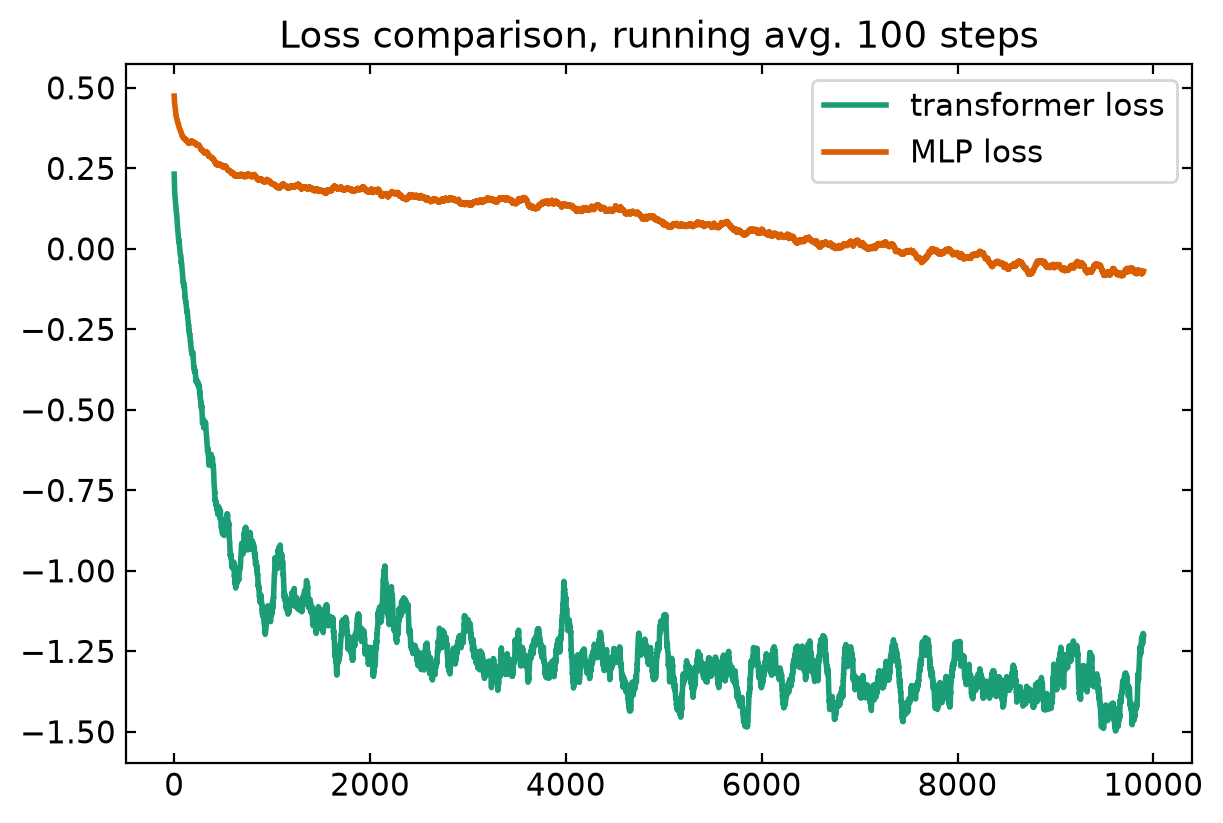

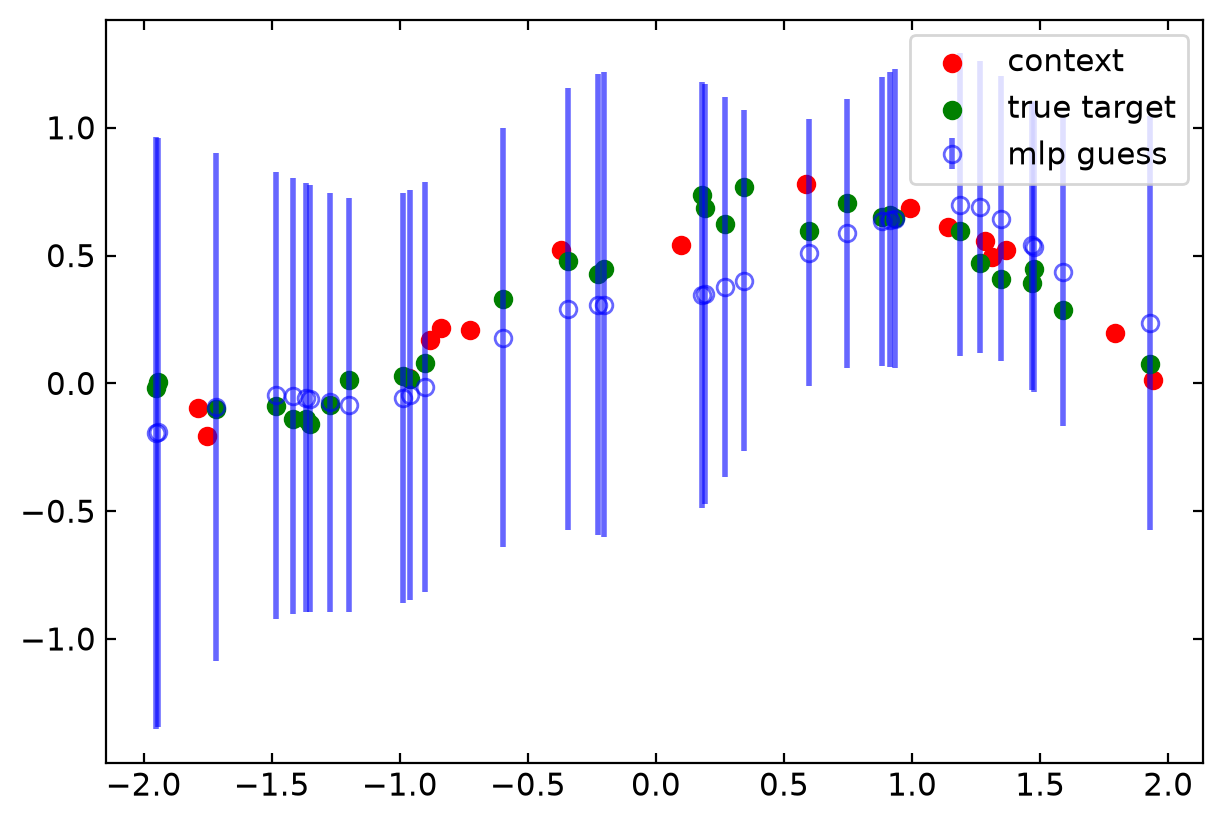

In [111]:
#plots of MLP performance

# plot loss MLP vs transformer
plt.figure(figsize=(6,4),dpi=200)
plt.plot(trainsteps[:len(running_avg)],running_avg,label="transformer loss")
window = 100
loss_arr_mlp = np.asarray(losses_mlp)
running_avg_mlp = np.convolve(losses_mlp, np.ones(window) / window, mode="valid")
plt.plot(trainsteps[:len(running_avg_mlp)],running_avg_mlp,label="MLP loss")
plt.title("Loss comparison, running avg. 100 steps")
plt.legend()

# plot mlp performance
thisxc = xc[0]
thisyc = yc[0]
thisxt = xt[0]
thisyt = yt[0]
plt.figure(figsize=(6,4),dpi=200)
plt.scatter(thisxc,thisyc,color='red',label='context')
plt.scatter(thisxt,thisyt,color="green",label='true target')

y_pred_mlp, log_var_mlp = run_mlp(params_mlp,xc,yc,xt,yt)
thisypred = y_pred_mlp[0]
thisvar = np.exp(log_var_mlp[0])
plt.errorbar(thisxt,thisypred,yerr=2*np.sqrt(thisvar),linestyle='',
             marker='o', markerfacecolor='none', markeredgecolor='blue',color='blue',
             alpha=0.6,label='mlp guess')
plt.legend()

---
## 4. Results 

- **Test error against the number of context points**, from 3 to 80, log-log, for the transformer, the MLP,
  and `gp_posterior` with the true lengthscale
- What happens to each model's predictions when you **shuffle the context points**?
- Plot something I didn't ask for!

In [124]:
ctx_list = np.geomspace(3,80,num=20)
ctx_list = np.unique(np.round(ctx_list).astype(int))
print(ctx_list)
cutoff = 13 # terrible code but lazy
ctx_list_cut = ctx_list[:13]

mse_tr = []
mse_mlp =[]
mse_gp = []

for n in ctx_list:
    k_test= jax.random.key(328+int(n))
    xc_test, yc_test, xt_test, yt_test, ell_test = sample_tasks(k_test, batch=512, n_ctx=n)

    run_transformer_jit = jax.jit(run_transformer)
    y_tr, _ = run_transformer_jit(params,xc_test,yc_test,xt_test,yt_test)
    y_gp,_ = gp_posterior(xc_test,yc_test,xt_test,ell_test)

    # calc MSE:
    mse_tr.append(jnp.mean((y_tr - yt_test)**2))
    mse_gp.append(float(jnp.mean((y_gp - yt_test)**2)))

    if n<30:
        y_mlp,_ = run_mlp(params_mlp,xc_test,yc_test,xt_test,yt_test) # note that after 30 must truncate
        mse_mlp.append(jnp.mean((y_mlp - yt_test)**2))


[ 3  4  5  6  7  8 10 12 14 17 20 24 28 34 40 48 57 67 80]


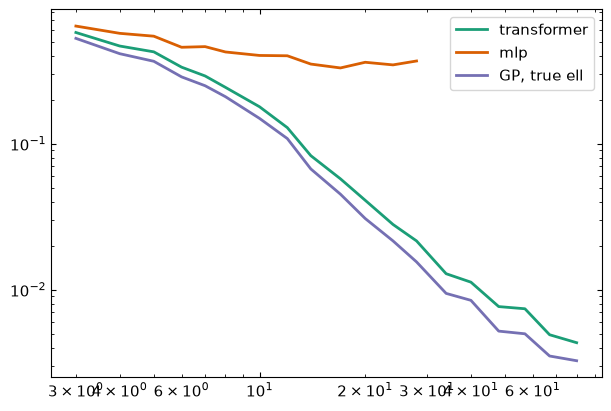

In [117]:
plt.figure()
plt.plot(ctx_list,mse_tr,label='transformer')
plt.plot(ctx_list_cut,mse_mlp,label='mlp')
plt.plot(ctx_list,mse_gp,label='GP, true ell')
plt.xscale('log')
plt.yscale('log')
plt.legend()

transformer max change after shuffle: 7.15e-07
mlp max change after shuffle: 3.01e-01


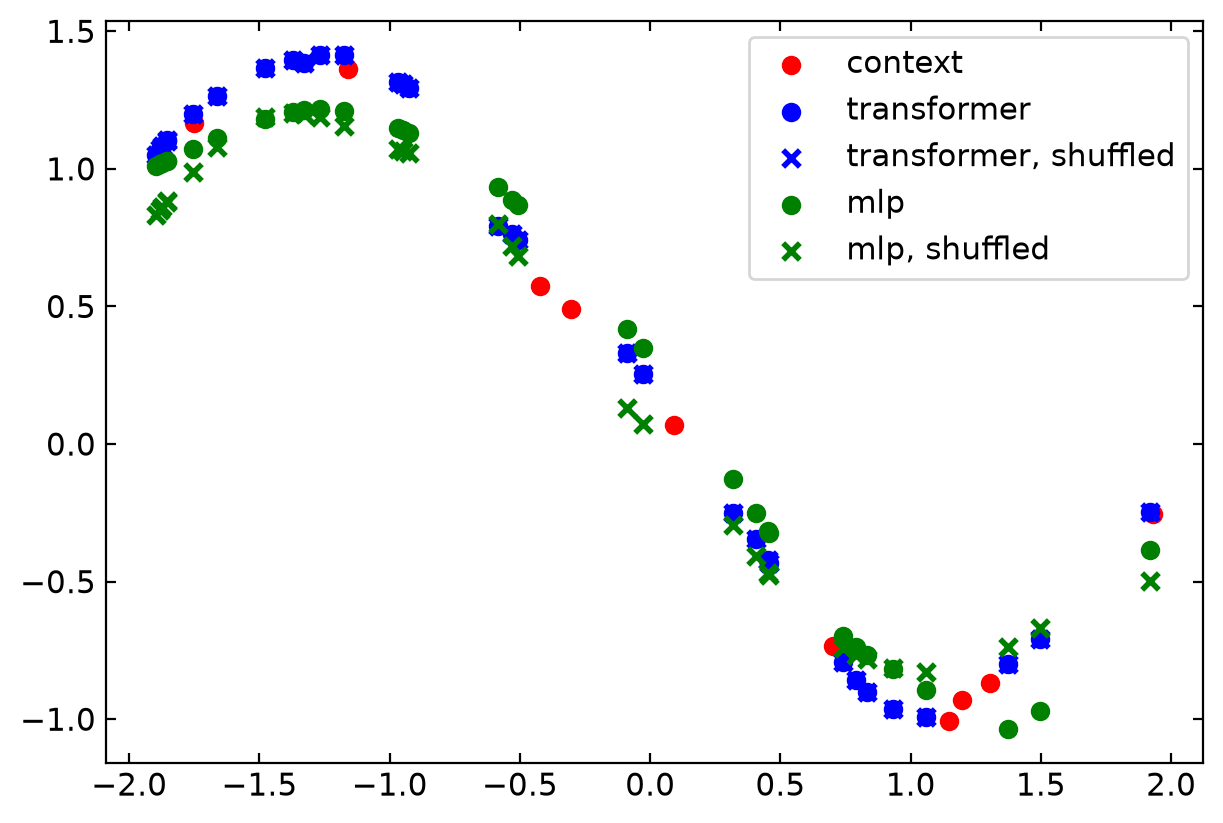

In [121]:
# shuffling points
n_ctx_s = 10
xc_s, yc_s, xt_s, yt_s, ell_s = sample_tasks(jax.random.key(7), batch=1, n_ctx=n_ctx_s)
perm = jax.random.permutation(jax.random.key(8), n_ctx_s)
xc_perm = xc_s[:, perm] # same perm for x and y so the (x,y) pairs stay together
yc_perm = yc_s[:, perm]

y_tr, _ = run_transformer(params,xc_s,yc_s,xt_s,yt_s)
y_tr_perm, _ = run_transformer(params,xc_perm,yc_perm,xt_s,yt_s)
y_mlp, _ = run_mlp(params_mlp,xc_s,yc_s,xt_s,yt_s)
y_mlp_perm, _ = run_mlp(params_mlp,xc_perm,yc_perm,xt_s,yt_s)

print(f"transformer max change after shuffle: {jnp.max(jnp.abs(y_tr - y_tr_perm)):.2e}")
print(f"mlp max change after shuffle: {jnp.max(jnp.abs(y_mlp - y_mlp_perm)):.2e}")

plt.figure(figsize=(6,4),dpi=200)
plt.scatter(xc_s[0],yc_s[0],color='red',label='context')
plt.scatter(xt_s[0],y_tr[0],color='blue',label='transformer')
plt.scatter(xt_s[0],y_tr_perm[0],color='blue',marker='x',label='transformer, shuffled')
plt.scatter(xt_s[0],y_mlp[0],color='green',label='mlp')
plt.scatter(xt_s[0],y_mlp_perm[0],color='green',marker='x',label='mlp, shuffled')
plt.legend()

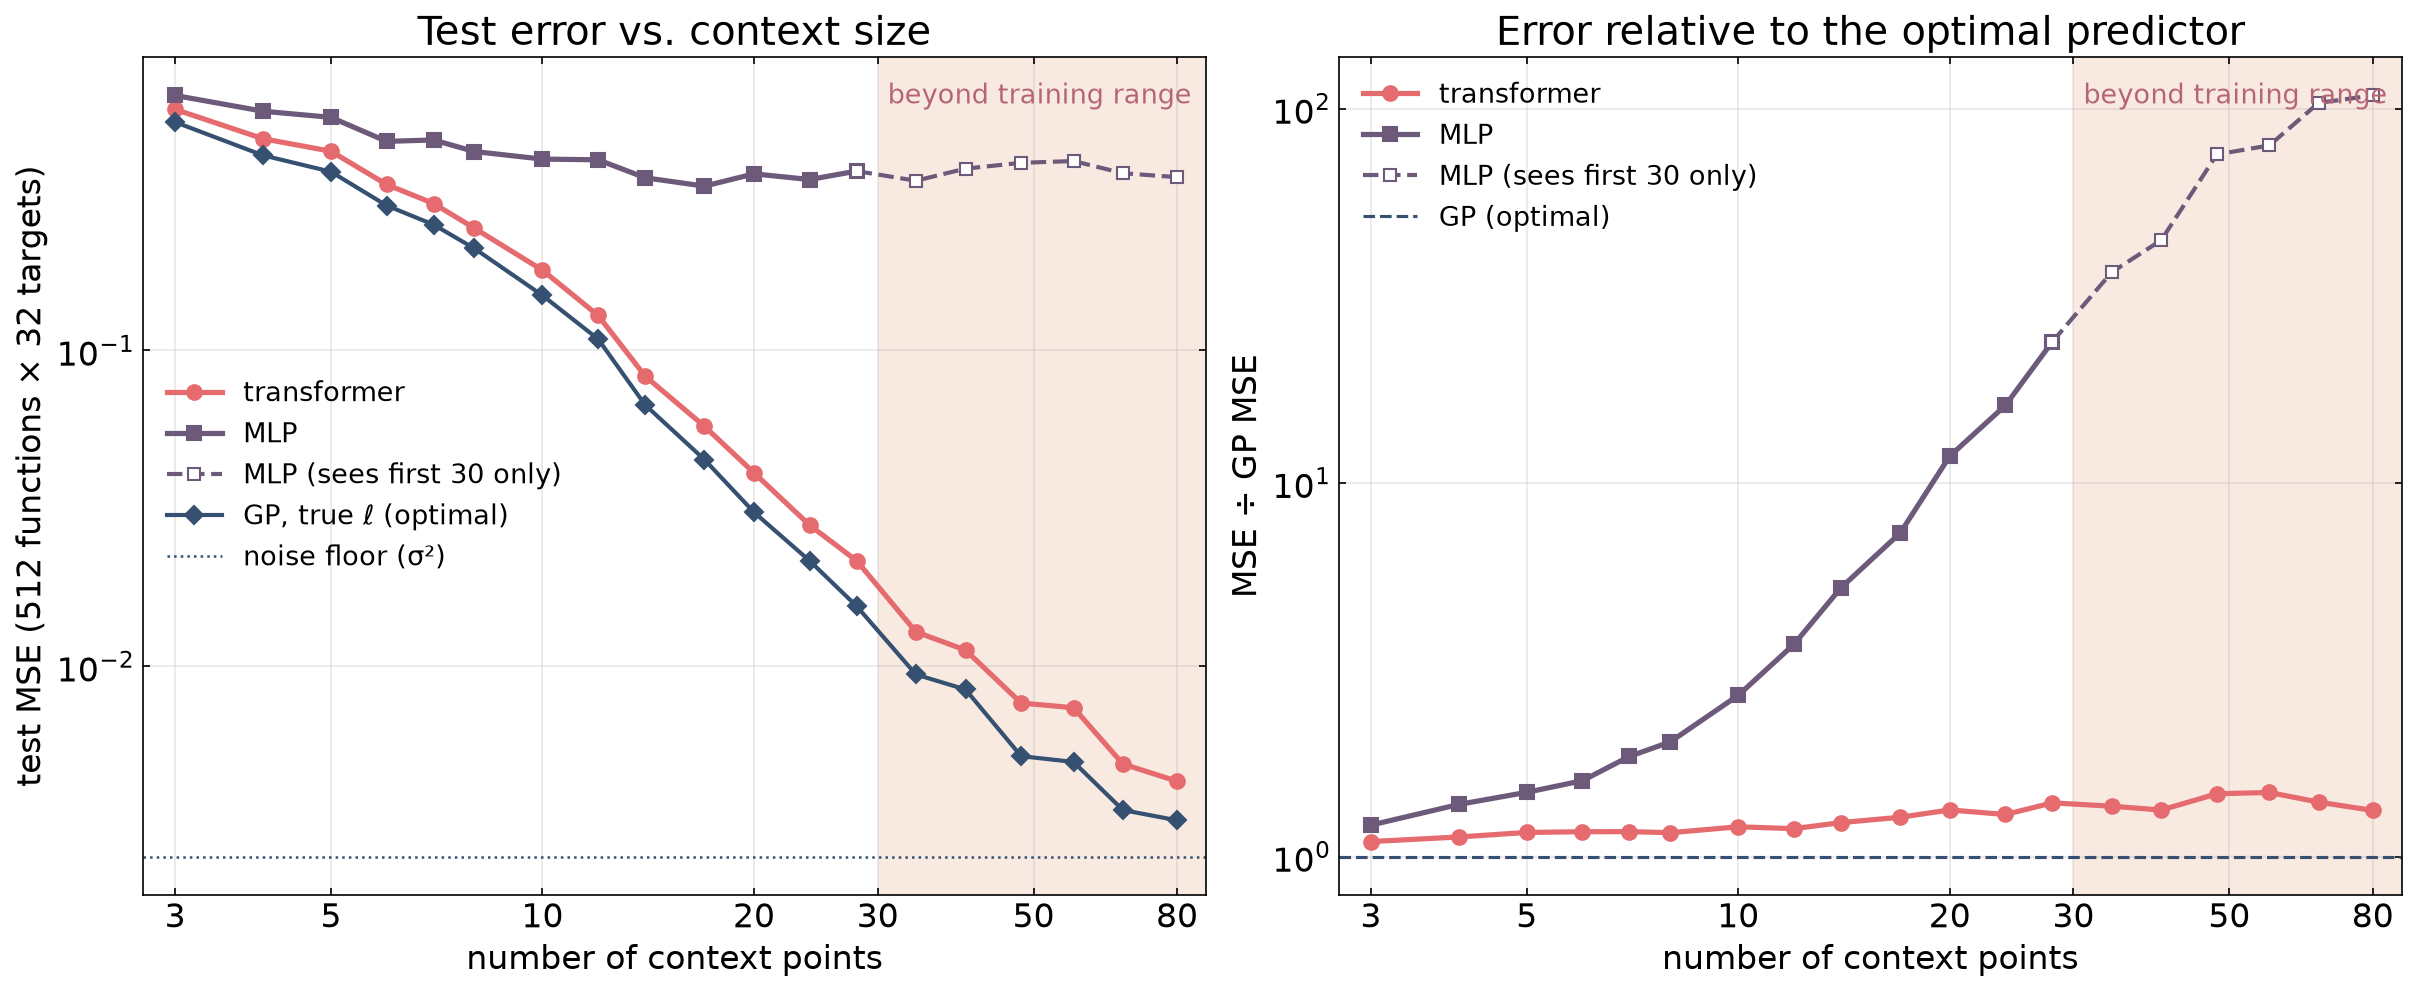

In [119]:
# [Claude-generated] Cleaned-up test error vs. number of context points.
# Left: MSE for each model on log-log axes, using mse_tr / mse_mlp / mse_gp from the cells above.
# The MLP is also scored past 30 context points, on the same test functions (same keys);
# run_mlp keeps only the first 30 there, so that part is dashed. Shaded: more context than any
# training batch had (3-30). Right: each model's MSE divided by the GP's, i.e. how many times
# worse than the best possible prediction (1 = optimal).
SUNSET = {"dusk": "#355070", "plum": "#6d597a", "rose": "#b56576",
          "coral": "#e56b6f", "peach": "#eaac8b", "gold": "#f6bd60"}

ctx_beyond = ctx_list[len(ctx_list_cut):]
mse_mlp_beyond = []
for n in ctx_beyond:
    xc_test, yc_test, xt_test, yt_test, _ = sample_tasks(jax.random.key(328 + int(n)), batch=512, n_ctx=int(n))
    # truncate here as well: run_mlp builds valid_mask before its own truncation, so >30 points breaks it
    y_mlp, _ = run_mlp(params_mlp, xc_test[:, :30], yc_test[:, :30], xt_test, yt_test)
    mse_mlp_beyond.append(float(jnp.mean((y_mlp - yt_test) ** 2)))

err_tr = np.array([float(m) for m in mse_tr])
err_gp = np.array([float(m) for m in mse_gp])
err_mlp = np.array([float(m) for m in mse_mlp])
err_mlp_beyond = np.concatenate([err_mlp[-1:], mse_mlp_beyond])   # start dashed line at the last solid point
ctx_mlp_beyond = np.concatenate([ctx_list_cut[-1:], ctx_beyond])

with plt.rc_context({"font.size": 16}):
    fig, (ax_err, ax_ratio) = plt.subplots(1, 2, figsize=(16, 6.5), dpi=150, layout="constrained")
    for ax in (ax_err, ax_ratio):
        ax.axvspan(30, ctx_list[-1] * 1.1, color=SUNSET["peach"], alpha=0.25, lw=0)
        ax.text(31, 0.97, "beyond training range", transform=ax.get_xaxis_transform(),
                va="top", color=SUNSET["rose"], fontsize=13)

    ax_err.plot(ctx_list, err_tr, "o-", color=SUNSET["coral"], lw=2.5, ms=7, label="transformer")
    ax_err.plot(ctx_list_cut, err_mlp, "s-", color=SUNSET["plum"], lw=2.5, ms=7, label="MLP")
    ax_err.plot(ctx_mlp_beyond, err_mlp_beyond, "s--", color=SUNSET["plum"], lw=2, ms=6, mfc="white",
                label="MLP (sees first 30 only)")
    ax_err.plot(ctx_list, err_gp, "D-", color=SUNSET["dusk"], lw=2, ms=6, label="GP, true ℓ (optimal)")
    ax_err.axhline(NOISE_STD**2, color=SUNSET["dusk"], lw=1.2, ls=":", label="noise floor (σ²)")
    ax_err.set_ylabel("test MSE (512 functions × 32 targets)")
    ax_err.set_title("Test error vs. context size")

    ax_ratio.plot(ctx_list, err_tr / err_gp, "o-", color=SUNSET["coral"], lw=2.5, ms=7, label="transformer")
    ax_ratio.plot(ctx_list_cut, err_mlp / err_gp[:len(err_mlp)], "s-", color=SUNSET["plum"], lw=2.5, ms=7, label="MLP")
    ax_ratio.plot(ctx_mlp_beyond, err_mlp_beyond / err_gp[len(err_mlp) - 1:], "s--", color=SUNSET["plum"],
                  lw=2, ms=6, mfc="white", label="MLP (sees first 30 only)")
    ax_ratio.axhline(1, color=SUNSET["dusk"], lw=1.5, ls="--", label="GP (optimal)")
    ax_ratio.set_ylabel("MSE ÷ GP MSE")
    ax_ratio.set_title("Error relative to the optimal predictor")

    for ax in (ax_err, ax_ratio):
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xticks([3, 5, 10, 20, 30, 50, 80], labels=["3", "5", "10", "20", "30", "50", "80"])
        ax.minorticks_off()
        ax.set_xlim(ctx_list[0] * 0.9, ctx_list[-1] * 1.1)
        ax.set_xlabel("number of context points")
        ax.grid(alpha=0.3)
        ax.legend(frameon=False, fontsize=13)
    plt.show()

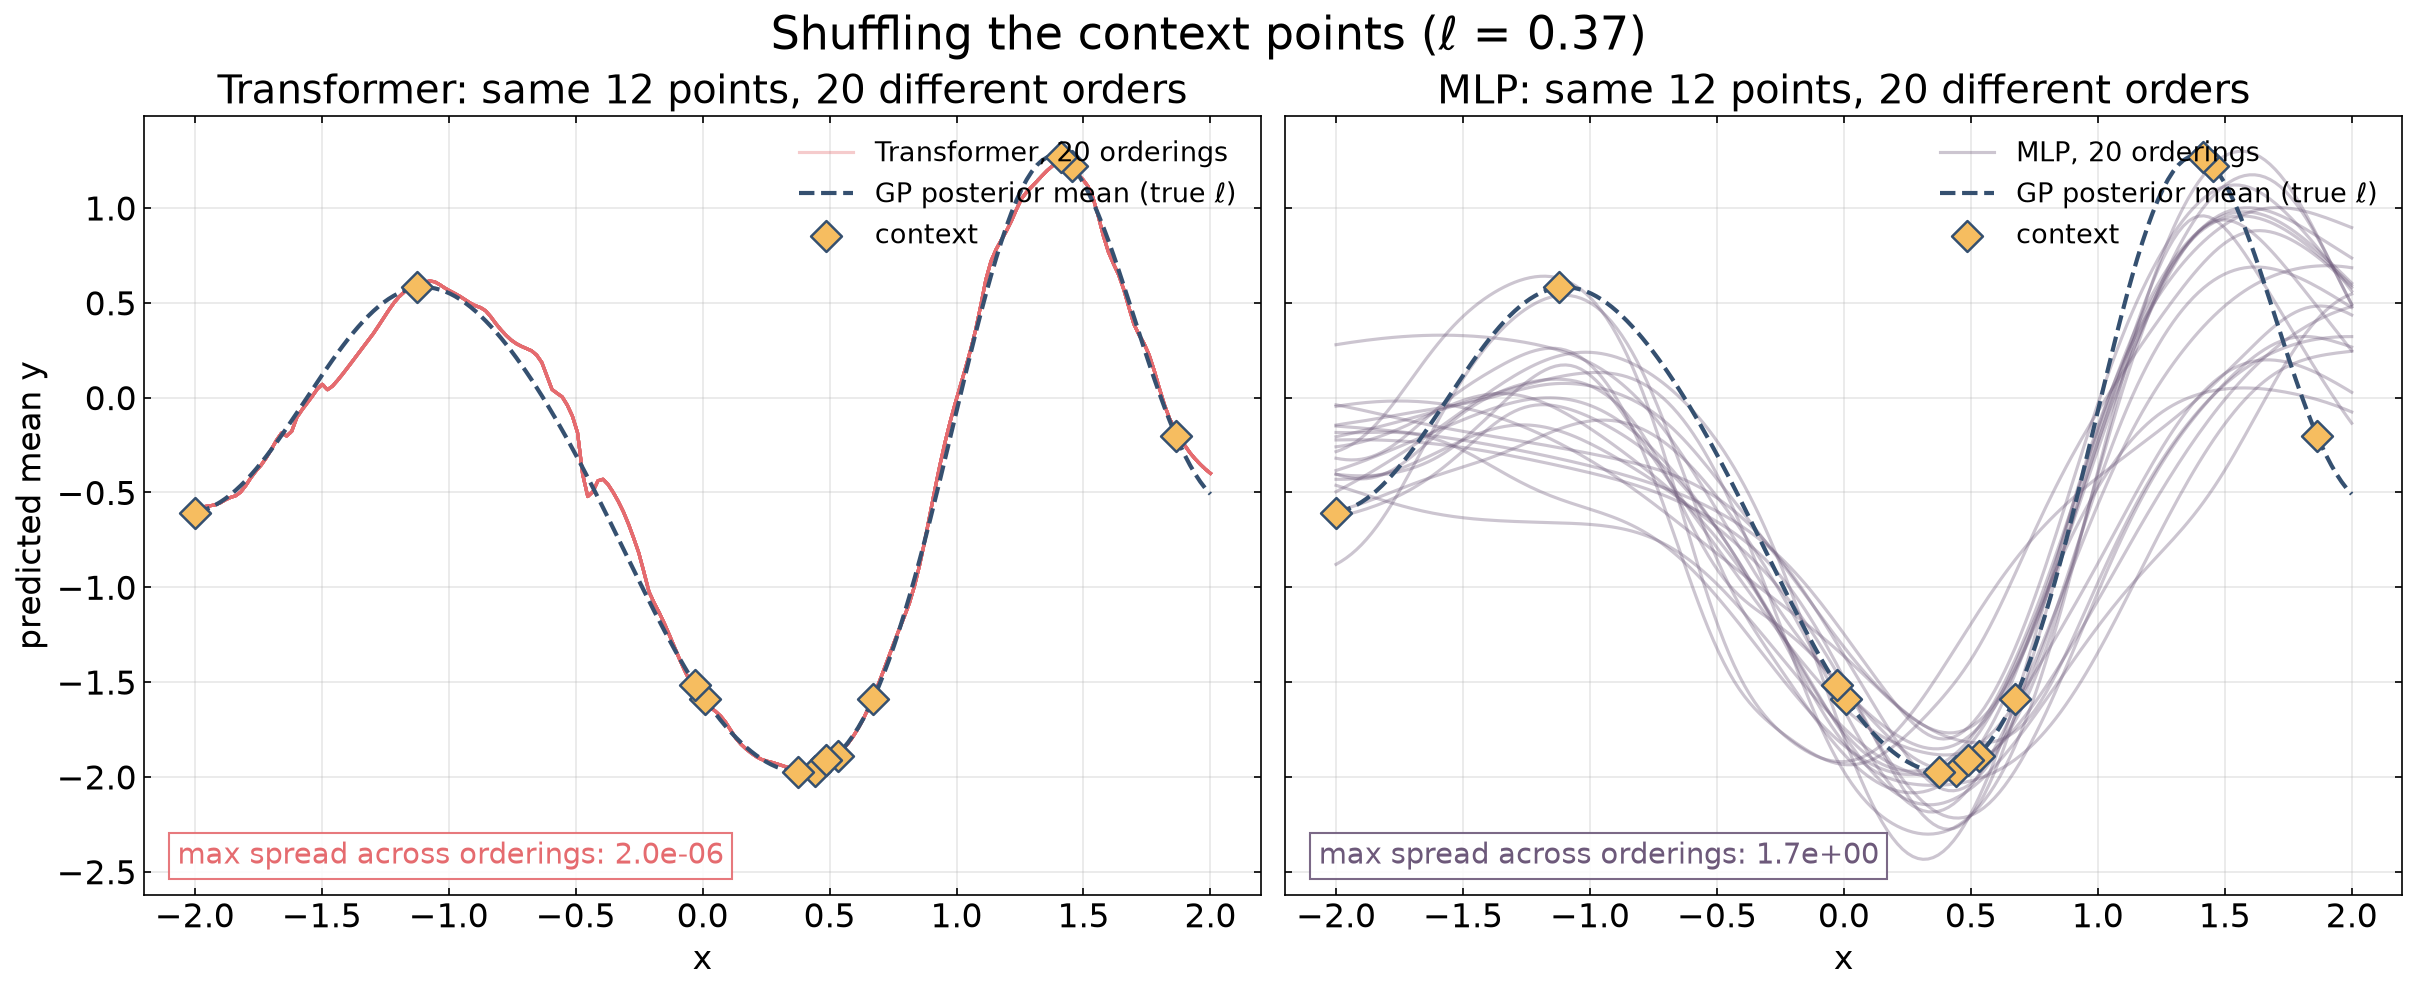

In [120]:
# [Claude-generated] What shuffling the context does to each model, on one function.
# The same 12 context points are fed in 20 different orders (the first is the original order)
# and each model predicts on a dense x-grid for every order. Every curve is drawn faintly,
# so curves that agree stack into one solid line and disagreements fan out. The transformer
# has no positional information and reads the context through a softmax-weighted sum, so all
# 20 curves should coincide. The MLP has separate input weights for each of its 30 slots, so
# moving a point to another slot changes its prediction.
SUNSET = {"dusk": "#355070", "plum": "#6d597a", "rose": "#b56576",
          "coral": "#e56b6f", "peach": "#eaac8b", "gold": "#f6bd60"}

n_ctx_show, n_shuffles = 12, 20
xc_1, yc_1, _, _, ell_1 = sample_tasks(jax.random.key(11), batch=1, n_ctx=n_ctx_show)
perms = [jnp.arange(n_ctx_show)] + [jax.random.permutation(k, n_ctx_show)
                                    for k in jax.random.split(jax.random.key(12), n_shuffles - 1)]
xc_sh = jnp.stack([xc_1[0, p] for p in perms])   # (n_shuffles, n_ctx): one row per ordering
yc_sh = jnp.stack([yc_1[0, p] for p in perms])

grid_x = jnp.linspace(-X_MAX, X_MAX, 200)
grid_b = jnp.broadcast_to(grid_x, (n_shuffles, grid_x.size))
pred_tr_sh, _ = run_transformer(params, xc_sh, yc_sh, grid_b, grid_b)   # yt arg is unused
pred_mlp_sh, _ = run_mlp(params_mlp, xc_sh, yc_sh, grid_b, grid_b)
gp_mean_1, _ = gp_posterior(xc_1, yc_1, grid_x[None], ell_1)

with plt.rc_context({"font.size": 16}):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), dpi=150, sharey=True, layout="constrained")
    for ax, preds, color, name in zip(axes, [pred_tr_sh, pred_mlp_sh], [SUNSET["coral"], SUNSET["plum"]],
                                      ["Transformer", "MLP"]):
        for i in range(n_shuffles):
            ax.plot(grid_x, preds[i], color=color, lw=1.5, alpha=0.35,
                    label=f"{name}, {n_shuffles} orderings" if i == 0 else None)
        ax.plot(grid_x, gp_mean_1[0], color=SUNSET["dusk"], lw=2, ls="--", label="GP posterior mean (true ℓ)")
        ax.scatter(xc_1[0], yc_1[0], s=110, marker="D", color=SUNSET["gold"], edgecolor=SUNSET["dusk"],
                   lw=1.2, zorder=5, label="context")

        spread = float(jnp.max(preds.max(axis=0) - preds.min(axis=0)))   # widest gap between orderings
        ax.text(0.03, 0.04, f"max spread across orderings: {spread:.1e}", transform=ax.transAxes,
                fontsize=14, color=color, bbox=dict(facecolor="white", edgecolor=color, alpha=0.9))
        ax.set_title(f"{name}: same {n_ctx_show} points, {n_shuffles} different orders")
        ax.set_xlabel("x")
        ax.grid(alpha=0.3)
        ax.legend(frameon=False, fontsize=13, loc="upper right")
    axes[0].set_ylabel("predicted mean y")
    fig.suptitle(f"Shuffling the context points (ℓ = {float(ell_1[0]):.2f})", fontsize=22)
    plt.show()

# Additional plots
Plot uncertainty vs. distance to nearest context point for MLP vs. transformer to get a sense of how the uncertainties actually are a response to confidence

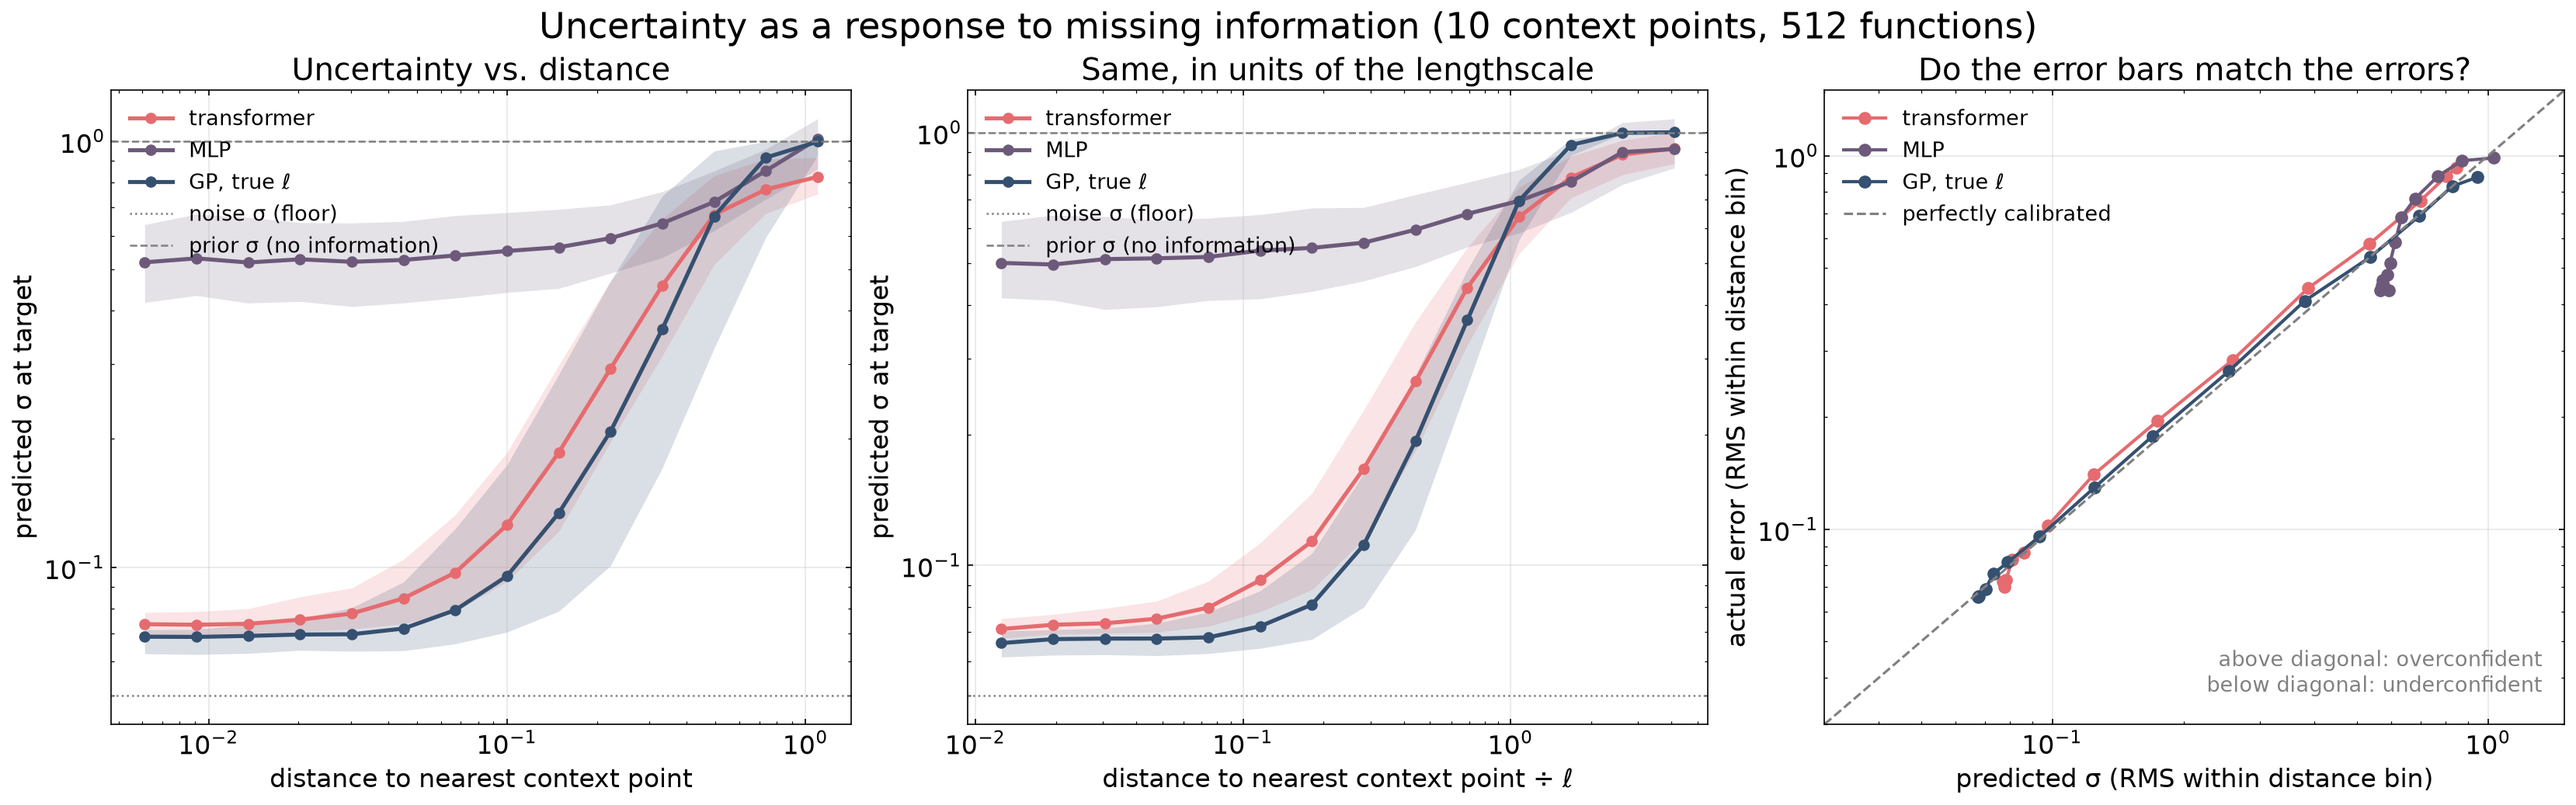

In [122]:
# [Claude-generated] Predicted uncertainty vs. distance to the nearest context point.
# 512 test functions with 10 context points each; every target gets a predicted σ from each model
# (σ = exp(log_var / 2) for the networks, sqrt of the posterior variance for the GP) and its distance
# to the closest context x. Lines are binned medians, bands the 25-75% range across targets.
# Left: raw distance. Middle: distance in units of the function's lengthscale ℓ. For the GP,
# uncertainty depends only on d/ℓ, so its curves collapse there; a network that has learned to
# infer ℓ from the context should collapse too. Right: is the uncertainty honest? For each distance
# bin, the typical predicted σ (RMS) against the actual RMS error; points on the diagonal mean
# the model's error bars are the right size.
SUNSET = {"dusk": "#355070", "plum": "#6d597a", "rose": "#b56576",
          "coral": "#e56b6f", "peach": "#eaac8b", "gold": "#f6bd60"}

n_ctx_u = 10
xc_u, yc_u, xt_u, yt_u, ell_u = sample_tasks(jax.random.key(404), batch=512, n_ctx=n_ctx_u, n_tgt=N_TGT)

mean_tr_u, logvar_tr_u = run_transformer(params, xc_u, yc_u, xt_u, yt_u)
mean_mlp_u, logvar_mlp_u = run_mlp(params_mlp, xc_u, yc_u, xt_u, yt_u)
mean_gp_u, cov_gp_u = gp_posterior(xc_u, yc_u, xt_u, ell_u)

dist = np.asarray(jnp.min(jnp.abs(xt_u[:, :, None] - xc_u[:, None, :]), axis=-1)).ravel()  # (512*32,)
dist_ell = dist / np.repeat(np.asarray(ell_u), N_TGT)
models = {
    "transformer": (mean_tr_u, np.exp(0.5 * np.asarray(logvar_tr_u)), SUNSET["coral"]),
    "MLP": (mean_mlp_u, np.exp(0.5 * np.asarray(logvar_mlp_u)), SUNSET["plum"]),
    "GP, true ℓ": (mean_gp_u, np.sqrt(np.asarray(jnp.diagonal(cov_gp_u, axis1=1, axis2=2))), SUNSET["dusk"]),
}


def binned_stats(x, y, bins, min_count=30):
    """Center, median, 25th and 75th percentile of y in each x-bin with enough points."""
    idx = np.digitize(x, bins) - 1
    rows = [(np.sqrt(bins[i] * bins[i + 1]), *np.percentile(y[idx == i], [50, 25, 75]))
            for i in range(len(bins) - 1) if np.sum(idx == i) >= min_count]
    return np.array(rows).T


dist_bins = np.geomspace(5e-3, 2.0, 16)
dist_ell_bins = np.geomspace(1e-2, 8.0, 16)

with plt.rc_context({"font.size": 16}):
    fig, (ax_d, ax_dl, ax_cal) = plt.subplots(1, 3, figsize=(22, 6.8), dpi=150, layout="constrained")
    for name, (mean_m, std_m, color) in models.items():
        std_flat = std_m.ravel()
        abs_err = np.abs(np.asarray(mean_m - yt_u)).ravel()
        for ax, d, bins in [(ax_d, dist, dist_bins), (ax_dl, dist_ell, dist_ell_bins)]:
            c, med, lo, hi = binned_stats(d, std_flat, bins)
            ax.fill_between(c, lo, hi, color=color, alpha=0.18, lw=0)
            ax.plot(c, med, "o-", color=color, lw=2.5, ms=6, label=name)

        # calibration: RMS predicted σ vs. RMS actual error, per raw-distance bin
        idx = np.digitize(dist, dist_bins) - 1
        keep = [i for i in range(len(dist_bins) - 1) if np.sum(idx == i) >= 30]
        rms_sigma = [np.sqrt(np.mean(std_flat[idx == i] ** 2)) for i in keep]
        rms_err = [np.sqrt(np.mean(abs_err[idx == i] ** 2)) for i in keep]
        ax_cal.plot(rms_sigma, rms_err, "o-", color=color, lw=2, ms=7, label=name)

    for ax in (ax_d, ax_dl):
        ax.axhline(NOISE_STD, color="gray", lw=1.2, ls=":", label="noise σ (floor)")
        ax.axhline(1.0, color="gray", lw=1.2, ls="--", label="prior σ (no information)")
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_ylabel("predicted σ at target")
    ax_d.set_xlabel("distance to nearest context point")
    ax_d.set_title("Uncertainty vs. distance")
    ax_dl.set_xlabel("distance to nearest context point ÷ ℓ")
    ax_dl.set_title("Same, in units of the lengthscale")

    lims = [0.03, 1.5]
    ax_cal.plot(lims, lims, color="gray", lw=1.5, ls="--", label="perfectly calibrated")
    ax_cal.set_xscale("log")
    ax_cal.set_yscale("log")
    ax_cal.set_xlim(lims)
    ax_cal.set_ylim(lims)
    ax_cal.set_xlabel("predicted σ (RMS within distance bin)")
    ax_cal.set_ylabel("actual error (RMS within distance bin)")
    ax_cal.set_title("Do the error bars match the errors?")
    ax_cal.text(0.97, 0.04, "above diagonal: overconfident\nbelow diagonal: underconfident",
                transform=ax_cal.transAxes, ha="right", va="bottom", fontsize=13, color="gray")

    for ax in (ax_d, ax_dl, ax_cal):
        ax.grid(alpha=0.3)
        ax.legend(frameon=False, fontsize=13, loc="upper left")
    fig.suptitle(f"Uncertainty as a response to missing information ({n_ctx_u} context points, 512 functions)",
                 fontsize=22)
    plt.show()

Plot an extrapolation of the model's prediction beyond the training range, x=[-4,4]. The Bayesian answer should go back to mean 0 with growing uncertainty

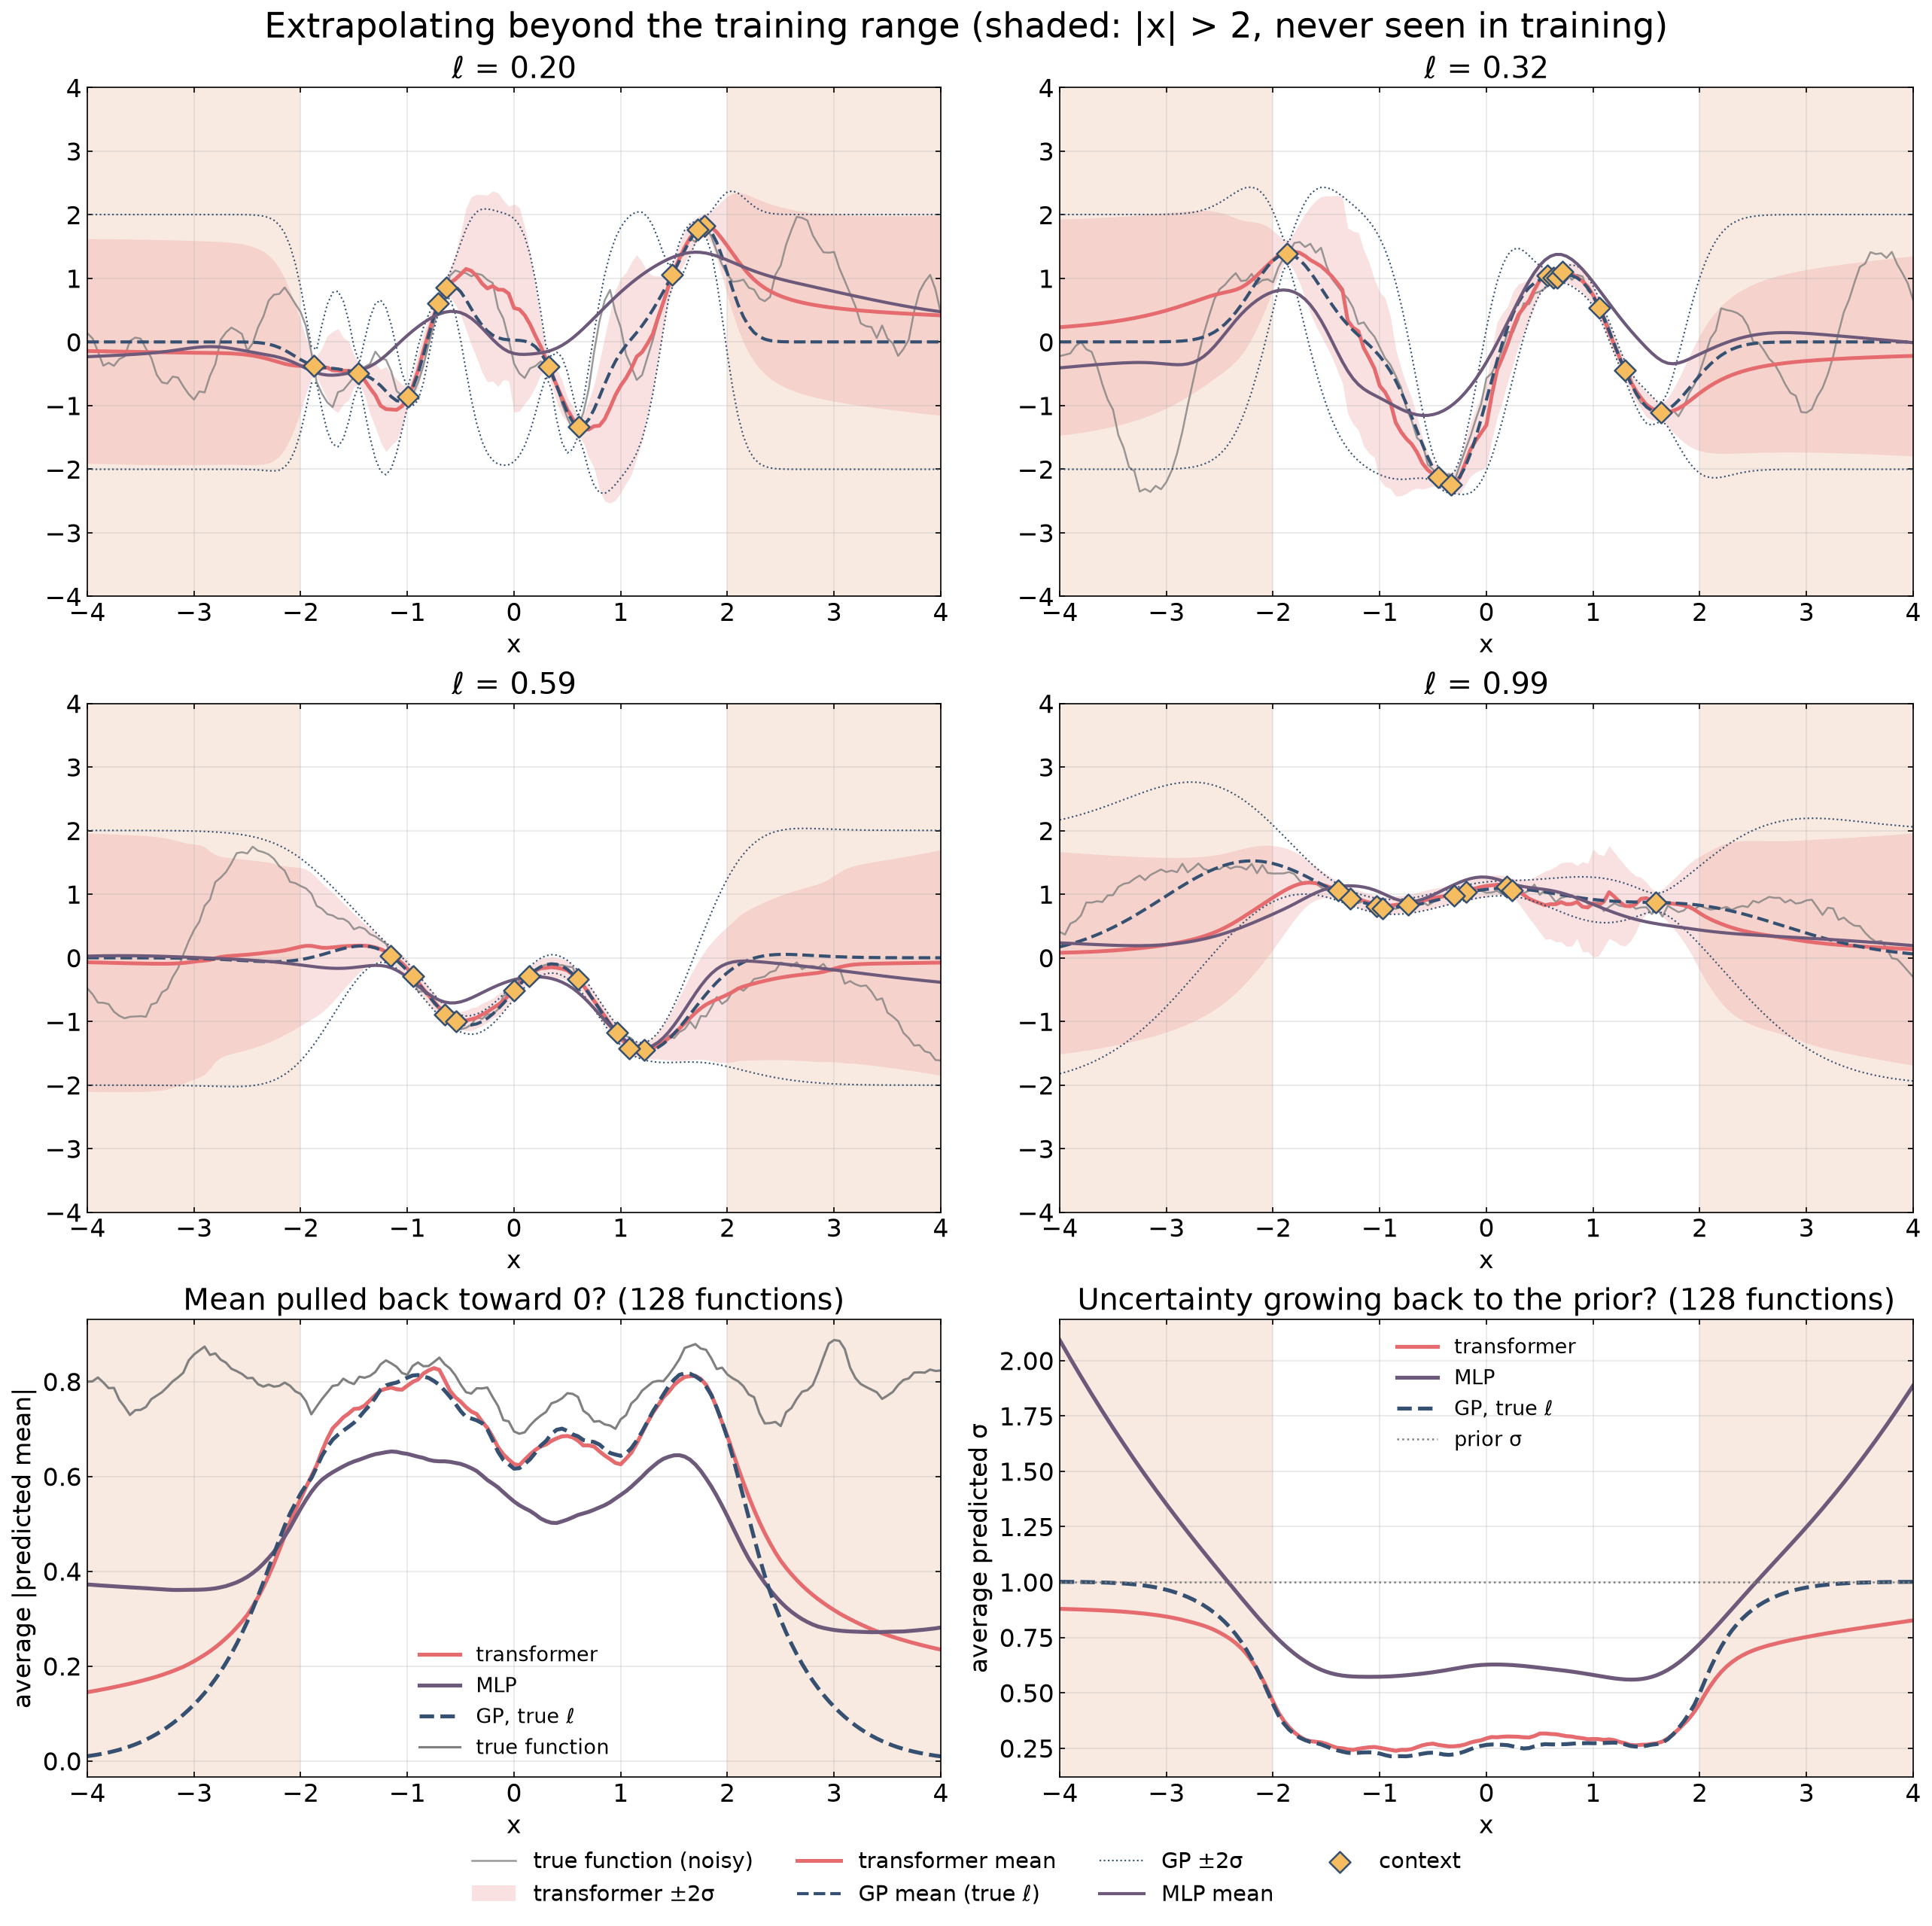

In [123]:
# [Claude-generated] Extrapolation beyond the training x-range.
# Context points (and every x seen in training) lie in [-2, 2]; here each model predicts on x in [-4, 4].
# sample_tasks with x_tgt=grid draws the true function jointly on the whole grid, so the gray line
# is the real continuation of the same function. Top four panels: individual functions (the MLP's
# band is left out to keep them readable; its σ is in the bottom right panel). Bottom: averages
# over 128 functions of |predicted mean| and predicted σ against x.
# The Bayesian answer (GP) relaxes to the prior outside the data, mean → 0 and σ → 1,
# over a distance of a few ℓ. The networks never saw |x| > 2 in training, so whatever they do
# there is pure extrapolation of what they learned inside.
SUNSET = {"dusk": "#355070", "plum": "#6d597a", "rose": "#b56576",
          "coral": "#e56b6f", "peach": "#eaac8b", "gold": "#f6bd60"}

X_EXT = 4.0
grid_ext = jnp.linspace(-X_EXT, X_EXT, 161)
n_ctx_x, n_funcs = 10, 128

xc_x, yc_x, _, ytrue_x, ell_x = sample_tasks(jax.random.key(2024), batch=n_funcs, n_ctx=n_ctx_x, x_tgt=grid_ext)
grid_bx = jnp.broadcast_to(grid_ext, (n_funcs, grid_ext.size))

mean_tr_x, logvar_tr_x = run_transformer(params, xc_x, yc_x, grid_bx, grid_bx)   # yt arg is unused
mean_mlp_x, logvar_mlp_x = run_mlp(params_mlp, xc_x, yc_x, grid_bx, grid_bx)
mean_gp_x, cov_gp_x = gp_posterior(xc_x, yc_x, grid_bx, ell_x)
preds_x = {
    "transformer": (np.asarray(mean_tr_x), np.exp(0.5 * np.asarray(logvar_tr_x)), SUNSET["coral"]),
    "MLP": (np.asarray(mean_mlp_x), np.exp(0.5 * np.asarray(logvar_mlp_x)), SUNSET["plum"]),
    "GP, true ℓ": (np.asarray(mean_gp_x), np.sqrt(np.asarray(jnp.diagonal(cov_gp_x, axis1=1, axis2=2))),
                   SUNSET["dusk"]),
}

# show four functions spanning the range of lengthscales
show = np.argsort(np.asarray(ell_x))[np.linspace(0, n_funcs - 1, 4).astype(int)]

with plt.rc_context({"font.size": 16}):
    fig, axd = plt.subplot_mosaic([["f0", "f1"], ["f2", "f3"], ["mean", "std"]], figsize=(17, 17), dpi=150,
                                  layout="constrained", height_ratios=[1, 1, 0.9])
    for j, b in enumerate(show):
        ax = axd[f"f{j}"]
        ax.plot(grid_ext, ytrue_x[b], color="gray", lw=1.2, alpha=0.8, label="true function (noisy)")
        m_tr, s_tr, c_tr = preds_x["transformer"]
        m_gp, s_gp, c_gp = preds_x["GP, true ℓ"]
        m_mlp, _, c_mlp = preds_x["MLP"]
        ax.fill_between(grid_ext, m_tr[b] - 2 * s_tr[b], m_tr[b] + 2 * s_tr[b], color=c_tr, alpha=0.2, lw=0,
                        label="transformer ±2σ")
        ax.plot(grid_ext, m_tr[b], color=c_tr, lw=2.4, label="transformer mean")
        ax.plot(grid_ext, m_gp[b], color=c_gp, lw=2, ls="--", label="GP mean (true ℓ)")
        for sign in (-1, 1):   # GP band as outlines so it doesn't muddy the transformer's band
            ax.plot(grid_ext, m_gp[b] + sign * 2 * s_gp[b], color=c_gp, lw=1, ls=":",
                    label="GP ±2σ" if sign == 1 else None)
        ax.plot(grid_ext, m_mlp[b], color=c_mlp, lw=2, label="MLP mean")
        ax.scatter(xc_x[b], yc_x[b], s=90, marker="D", color=SUNSET["gold"], edgecolor=SUNSET["dusk"],
                   lw=1.2, zorder=5, label="context")
        ax.set_title(f"ℓ = {float(ell_x[b]):.2f}")
        ax.set_ylim(-4, 4)

    for name, (m, s, color) in preds_x.items():
        ls = "--" if name.startswith("GP") else "-"
        axd["mean"].plot(grid_ext, np.mean(np.abs(m), axis=0), color=color, lw=2.5, ls=ls, label=name)
        axd["std"].plot(grid_ext, np.mean(s, axis=0), color=color, lw=2.5, ls=ls, label=name)
    axd["mean"].plot(grid_ext, np.mean(np.abs(np.asarray(ytrue_x)), axis=0), color="gray", lw=1.5,
                     label="true function")
    axd["mean"].set_ylabel("average |predicted mean|")
    axd["mean"].set_title(f"Mean pulled back toward 0? ({n_funcs} functions)")
    axd["std"].axhline(1.0, color="gray", lw=1.2, ls=":", label="prior σ")
    axd["std"].set_ylabel("average predicted σ")
    axd["std"].set_title(f"Uncertainty growing back to the prior? ({n_funcs} functions)")

    for ax in axd.values():
        for edge in (-1, 1):
            ax.axvspan(edge * X_MAX, edge * X_EXT, color=SUNSET["peach"], alpha=0.25, lw=0)
        ax.set_xlim(-X_EXT, X_EXT)
        ax.set_xlabel("x")
        ax.grid(alpha=0.3)
    axd["mean"].legend(frameon=False, fontsize=13)
    axd["std"].legend(frameon=False, fontsize=13)
    handles, labels = axd["f0"].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside lower center", ncols=4, frameon=False, fontsize=14)
    fig.suptitle("Extrapolating beyond the training range (shaded: |x| > 2, never seen in training)", fontsize=22)
    plt.show()

---
## 5. Flow matching

Now generate posteriors over functions. Target tokens carry a noisy value $y_t$ instead of 0, the time $t$ is embedded and added
to every token, and the head outputs one velocity per target. Same network as before.

Train on the straight path from noise $\epsilon \sim \mathcal{N}(0, 1)$ to data:

$$y_t = (1-t)\,\epsilon + t\,y, \qquad \mathcal{L} = \big\| v_\theta(y_t, t \mid \text{context}) - (y - \epsilon) \big\|^2$$

Sample by integrating $dy/dt = v_\theta$ from $t=0$ to $1$ with Euler, 50 steps.